## Rouse polymer

In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os
from viz_util import overdamped_langevin as lgv

### Recovering the Arrhenius exit time

#### Checking the equilibrium distribution for a harmonic potential

In [2]:
k = 3
gamma = 0.5
dt = 0.01 * gamma / k   # choose much smaller than characteristic time
sim = lgv.OverdampedHarmonicLangevin(
    tau=500000*dt, dim=1, N=1, dt=dt,
    T=1.0, F=lambda r: -k * r,
    gamma = gamma, nskip = 10
)
sim.generate()

empirical Var(r) = 0.3283469173095977   expected = 0.3333333333333333


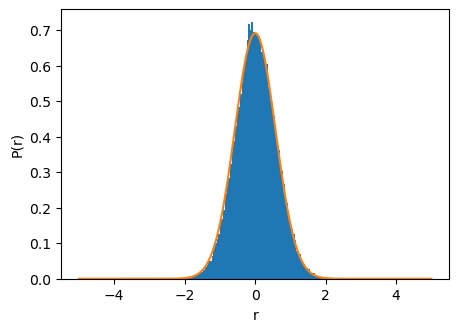

In [3]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

xs = np.linspace(-5, 5, 500)
var = sim.kB * sim.T_bath / k       # OU stationary variance for F = -k r
dist = np.exp(-xs**2/(2*var)) / np.sqrt(2*np.pi*var)

# discard burn-in (a few relaxation times tau_relax = gamma/k)
burn = int(5 * gamma / k / sim.dt)
ax.hist(sim.r[burn:,0,0].flatten(), bins=100, density=True)
# ax.hist(sim.r[-1,0,:].flatten(), bins=100, density=True)
ax.plot(xs, dist)
ax.set_xlabel("r"); ax.set_ylabel("P(r)")
print("empirical Var(r) =", sim.r[burn:,0,0].var(), "  expected =", var)

### A simple potential with well and barrier 

In [72]:
# Double-well potential: 1/(100|r|) keeps r > 0, Gaussian creates the barrier,
# 0.01 r^2 confines at large r.
args = (100, 1.0, 0.48, 0.01)


left well  : r=0.010, U=0.360, ω_well=0.896
barrier    : r=1.009,  U=1.010,  ω_bar =1.436
ΔU = 0.650


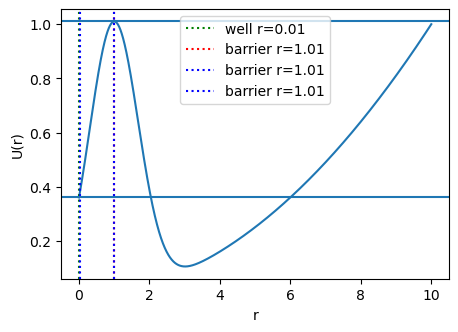

In [73]:
def U(x, *args):
    a, b, c, d = args
    # return 1.0 / np.abs(a * x) + np.exp(-(x - b) ** 2 / (2 * c)) + d * x ** 2
    return np.exp(-(x - b) ** 2 / (2 * c)) + d * x ** 2


def F(x, *args):
    """Analytic force F = -dU/dx (only valid for x > 0)."""
    a, b, c, d = args
    # return 1.0 / (a * x ** 2) + (x - b) / c * np.exp(-(x - b) ** 2 / (2 * c)) - 2 * d * x
    return (x - b) / c * np.exp(-(x - b) ** 2 / (2 * c)) - 2 * d * x


# --- locate left well, barrier; compute ΔU and curvatures ---
xs = np.linspace(1e-2, 10, 5000)
U_vals = U(xs, *args)

left = xs < 2.0
right = xs > 2.0
i_well = np.argmin(U_vals[left])
i_barrier = (np.argmax(U_vals[left]) if False
             else np.argmax(U_vals * ((xs > xs[left][i_well]) & (xs < 3.5))))

x_well, U_well = xs[left][i_well], U_vals[left][i_well]
x_bar,  U_bar = xs[i_barrier],   U_vals[i_barrier]
dU = U_bar - U_well
x_bar_a = 0.05
x_bar_b = x_bar

# numerical curvatures


def d2U(x):
    h = 1e-5
    return (U(x + h, *args) - 2 * U(x, *args) + U(x - h, *args)) / h ** 2


omega_well = np.sqrt(d2U(x_well))     # >0
omega_bar = np.sqrt(-d2U(x_bar))      # |U''| at the saddle

print(f"left well  : r={x_well:.3f}, U={U_well:.3f}, ω_well={omega_well:.3f}")
print(f"barrier    : r={x_bar:.3f},  U={U_bar:.3f},  ω_bar ={omega_bar:.3f}")
print(f"ΔU = {dU:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.plot(xs, U_vals)
ax.axvline(x_well, color="g", ls=":", label=f"well r={x_well:.2f}")
ax.axvline(x_bar,  color="r", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_a,  color="b", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_b,  color="b", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axhline(U_well)
ax.axhline(U_bar)
ax.set_xlabel("r")
ax.set_ylabel("U(r)")
ax.legend()

#### Simulating Langevin under that potential

In [60]:
# --- parameter selection -------------------------------------------------
# 1) Temperature: ΔU/(kBT) in [3, 7] is the Arrhenius sweet spot --- escape
#    is rare enough to be exponentially distributed, frequent enough to
#    collect statistics in reasonable wall-clock time.
T_bath = 0.28                    # -> ΔU/T ≈ 4.6 here
gamma  = 0.3
kB     = 1.0

# 2) Time step: needs to satisfy BOTH
#       dt < (1/10) * γ / max|U''|         (drift stability)
#       √(2 kBT/γ * dt) << min feature size (noise step << well width)
relax_well = gamma / d2U(x_well)              # γ / U''(well)
relax_bar  = gamma / abs(d2U(x_bar))          # γ / |U''(barrier)|
dt_drift   = 0.01 * min(relax_well, relax_bar)
noise_step_target = 0.1 * (x_bar - x_well)    # << 1/10 of well-to-barrier distance
dt_noise   = noise_step_target ** 2 / (2 * kB * T_bath / gamma)
dt         = min(dt_drift, dt_noise)
print(f"dt_drift = {dt_drift:.4f}, dt_noise = {dt_noise:.4f}  ->  using dt = {dt:.4f}")

# 3) Total time: a few mean Kramers escape times so we observe many exits.
# tau_K = (2 * np.pi * gamma / (omega_well * omega_bar)) * np.exp(dU / (kB * T_bath))

dV_R = -F(0, *args)
tau_K = ((gamma / dV_R) * ((np.sqrt(2*np.pi*kB*T_bath))/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - 0)/ (kB*T_bath))))
tau   = 50 * tau_K
print(f"Kramers mean exit time ≈ {tau_K:.2f},  using tau = {tau:.1f}")

# 4) Reflecting wall well clear of the 1/r singularity, but where U(r_min) is
#    so high that the equilibrium weight there is negligible (~ exp(-U/T)).
r_min = 0.01
print(f"U(r_min)/T = {U(r_min, *args)/T_bath:.1f}  (should be >> 1)")

# 5) Number of trajectories — limited by RAM: shape (n, dim, N).
N = 1000
nskip = 2
print(f"n_steps = {int(tau/dt)},  memory ≈ {int(tau/dt)*N*8/1e6/nskip:.0f} MB per array")

sim = lgv.OverdampedHarmonicLangevin(
    tau=tau, dim=1, N=N, dt=dt,
    T=T_bath, gamma=gamma, kB=kB,
    F=lambda r: F(r, *args),
    r0=x_well, nskip=nskip,
    r_min=r_min,
    seed=3,
    ab = (x_bar_a, x_bar_b),
)
sim.generate()
print("min(r) =", sim.r.min(), " (should be ≥ r_min)")

dt_drift = 0.0015, dt_noise = 0.0077  ->  using dt = 0.0015
Kramers mean exit time ≈ 7.48,  using tau = 374.2
U(r_min)/T = 0.8  (should be >> 1)
n_steps = 257262,  memory ≈ 1029 MB per array
min(r) = 0.01  (should be ≥ r_min)


#### Checking the Boltzmann distribution

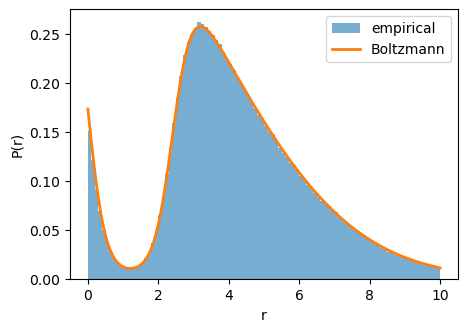

In [56]:
# --- Boltzmann sampling check -----------------------------
burn = int(0.2 * sim.ns)
r_traj = sim.r[burn:, 0, :]                          # shape (n, N)

# samples = r_traj[mask]
samples = r_traj[::100].flatten()

# Boltzmann on the left basin (renormalized over r < x_bar)
xs = np.linspace(1e-2, 10, 5000)
left_mask = xs < x_bar
# P_left = np.exp(-(U_vals - U_well) / T_bath)  * left_mask
# P_left /= np.trapz(P_left, xs)

# Boltzmann on the whole support
P_full = np.exp(-(U_vals - U_well) / T_bath)
P_full /= np.trapz(P_full, xs)

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.hist(samples, bins=100, density=True, range=(r_min, 10), alpha=0.6,
        label="empirical")
ax.plot(xs, P_full, lw=2, label="Boltzmann")
ax.set_xlabel("r"); ax.set_ylabel("P(r)"); ax.legend()

In [ ]:
out_dir = "media/figures/20260606"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "empirical_vs_boltzmann_for_arbitrary_potential_high_T.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260606/empirical_vs_boltzmann_for_arbitrary_potential_high_T.pdf


#### Recovering the Kramers exit rate

In [12]:
r_traj = sim.r[:, 0, :]
limit = x_bar
crossed = r_traj > limit
first_exit = np.where(crossed.any(0), crossed.argmax(0), sim.ns)
mask = np.arange(sim.ns)[burn:, None] < first_exit[None, :]

In [61]:
def scalar_reference(positions, a, b):
    positions = np.asarray(positions, dtype=float)
    if positions.ndim == 1:
        positions = positions[:, None]
    n, N = positions.shape
    A_intervals = [[] for _ in range(N)]
    B_intervals = [[] for _ in range(N)]
    in_A = positions[0] <= a
    in_B = positions[0] > a
    A_entry = np.zeros(N)
    B_entry = np.zeros(N)
    for i in range(1, n):
        r = positions[i]
        for k in range(N):
            if r[k] >= b and in_A[k]:
                B_entry[k] = i
                A_intervals[k].append(B_entry[k] - A_entry[k])
                in_A[k] = False
                in_B[k] = True
            if r[k] <= a and in_B[k]:
                A_entry[k] = i
                B_intervals[k].append(A_entry[k] - B_entry[k])
                in_B[k] = False
                in_A[k] = True
    return A_intervals, B_intervals

r_traj = sim.r[:, 0, :]

A_intervals_ref, B_intervals_ref = scalar_reference(r_traj, x_bar_a, x_bar_b)

In [62]:
first_exit_cum = []
first_entry_cum = []

for i in range(sim.N):
    # first_exit_cum = np.concatenate((first_exit_cum, sim.A_intervals[i][10:]))
    # first_entry_cum = np.concatenate((first_entry_cum, sim.B_intervals[i][10:]))

    first_exit_cum = np.concatenate((first_exit_cum, A_intervals_ref[i][1:]))
    first_entry_cum = np.concatenate((first_entry_cum, B_intervals_ref[i][1:]))

empirical rate  k = 1/<T_exit> = 0.3107
Kramers   rate  k             = 0.2672
ratio empirical / Kramers     = 1.16


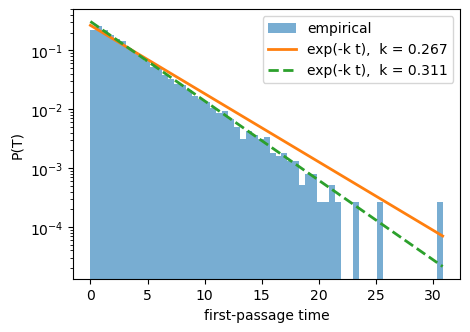

In [63]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] > limit).any(0)
# fpt = first_exit[exited] * sim.dt * sim.nskip
fpt = first_exit_cum * sim.dt * sim.nskip
# print(f"{exited.sum()}/{sim.N} trajectories exited")

tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kB*T_bath)/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - 0)/ (kB*T_bath))))

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 60)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_kramers:.3f}")
ax.plot(t_grid, k_emp * np.exp(-k_emp * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}", linestyle="dashed")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")

### Rouse potential + attractive well

#### Load data

In [424]:
import json, glob
import numpy as np

# _data_dir = "data/20260528/rouse_mfpt_attractive"
# _data_dir = "data/20260611/rouse_mfpt_attractive"
# _data_dir = "data/20260612/rouse_mfpt_attractive"
_data_dir = "data/20260615/rouse_mfpt_attractive"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _cpu_id = list(_raw.keys())[0]
    for _run_id, _run in _raw[_cpu_id].items():
        _alpha = _run["alpha"]
        data[_alpha] = _run

# --- sort alphas ---
alphas = np.array(sorted(data.keys()))
nparams = len(alphas)

# infer params from first entry
_first = data[alphas[0]]
params         = _first["rouse_params"]
nsteps_distance = int(params["nsteps"] / _first["sample_skip"])
# nsteps_full     = params["nsteps_full"]
dt              = params["dt"]

t_grid_distance = np.arange(nsteps_distance) * dt
# t_grid_full     = np.arange(nsteps_full) * dt
nsteps_pot     = len(_first["total_potential"])

# pre-allocate (sizes inferred from first entry)
# _nfpt = len(_first["contact_times"])
# _nicdf = len(_first["inverse_cdf"])
# _nhist = len(_first["hist_centers"])
# _nmsd  = len(_first["msd_bead1"])

distance_traj    = np.empty((nparams, nsteps_distance))
# contact_times    = [None] * nparams   # variable-length per alpha
# inverse_cdf      = [None] * nparams
# hist_centers     = np.empty((nparams, _nhist))
# hist_counts      = np.empty((nparams, _nhist))
# msd_bead1        = np.empty((nparams, _nmsd))
# msd_beadMid      = np.empty((nparams, _nmsd))
# msd_pairDistance = np.empty((nparams, _nmsd))
total_potential    = np.empty((nparams, nsteps_pot))
runtime_min      = np.empty(nparams)

for _ic, _alpha in enumerate(alphas):
    _r = data[_alpha]
    distance_traj[_ic]    = np.array(_r["distance_traj"])
    total_potential[_ic]  = np.array(_r["total_potential"])
    # contact_times[_ic]    = np.array(_r["contact_times"])
    # inverse_cdf[_ic]      = np.array(_r["inverse_cdf"])
    # hist_centers[_ic]     = np.array(_r["hist_centers"])
    # hist_counts[_ic]      = np.array(_r["hist_counts"])
    # msd_bead1[_ic]        = np.array(_r["msd_bead1"])
    # msd_beadMid[_ic]      = np.array(_r["msd_beadMid"])
    # msd_pairDistance[_ic] = np.array(_r["msd_pairDistance"])
    runtime_min[_ic]      = _r["runtime_min"]

In [425]:
from viz_util.bvp_solver import (
    Parameters, d2fb_dphi2, 
)

keya = 10
p_sim = data[alphas[keya]]["surface_params"]

p = Parameters(
    nb=p_sim["nb"],
    chi_b=p_sim["chi_b"],
    omega_b=p_sim["omega_b"],
    kappa=p_sim["kappa"],
    phi_inf=p_sim["phi_inf"],
    L=10.0,
    eps=1e-6,
    R=p_sim["R"],
    conserve_volume=False,
    parallel_plates=False
)

kuhnLength = data[alphas[keya]]["rouse_params"]["kuhn_length"]
beadSep = data[alphas[keya]]["rouse_params"]["bead_separation"]

barrier    : r=3.890,  U=-2.634,  ω_bar =0.959
ΔU = 5.988


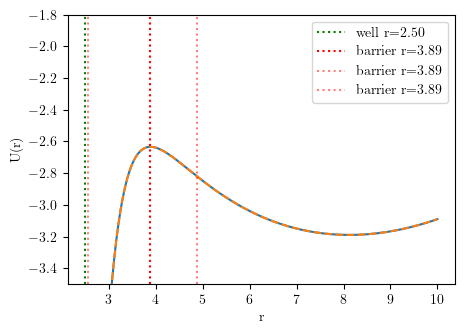

In [426]:
def U(r, *args):
    R, h0, kappa, lam, a, s = args

    # profile = np.where(r >= R, np.exp(-lam*(r-R))*R/r, 1)
    profile = np.exp(-lam*(r-R))*R/r

    return (
        - 2 * np.log(r) + 3*r**2/(2*s*a**2) 
        - 4*np.pi*R**2*h0**2*profile/(kappa*(lam+1/R))
    )

def F(r, *args):
    """Analytic force F = -dU/dx (only valid for x > 0)."""
    R, h0, kappa, lam, a, s = args

    # attrForce = np.where(r >= R, 1, 0)
    attrForce = 1

    return (
        2 / r - 3*r/(s*a**2) 
        - attrForce*4*np.pi*R**3*h0**2*np.exp(-lam*(r-R))*(lam/r+1/r**2)/(kappa*(lam+1/R))
    )

# --- locate left well, barrier; compute ΔU and curvatures ---
xs = np.linspace(p.R, p.L, 500)

lam = np.sqrt(d2fb_dphi2(p.phi_inf, p))
args = (p.R, p.omega_b, p.kappa, lam, kuhnLength, beadSep)
U_vals = U(xs, *args)
U_sim = data[alphas[keya]]["total_potential"]

# left = xs < 10
i_well = np.argmin(U_vals)
x_well, U_well = xs[i_well], U_vals[i_well]

# Barrier = first zero-crossing of dU/dx past the well.
# At a maximum the force F = -dU/dx flips from - to +; the first sign change
# of F (scanning outward from the well) marks the ridge between the two wells.
F_vals = F(xs, *args)
after_well = xs > x_well
sign_change = (np.sign(F_vals[after_well][:-1]) < 0) & (np.sign(F_vals[after_well][1:]) > 0)
i_cross = np.argmax(sign_change)  # first True; argmax stops at the first one
assert sign_change.any(), "no F-sign-change found past the well — barrier not located"

# linear interpolation between the bracketing samples for a sub-grid root
x_lo = xs[after_well][i_cross]
x_hi = xs[after_well][i_cross + 1]
F_lo, F_hi = F_vals[after_well][i_cross], F_vals[after_well][i_cross + 1]
x_bar = x_lo - F_lo * (x_hi - x_lo) / (F_hi - F_lo)
eps = 0.2
x_bar_a = p.R + 0.05
x_bar_b = x_bar+1
U_bar = U(x_bar, *args)

dU = U_bar - U_well

# numerical curvatures
def d2U(x):
    h = 1e-3
    return (U(x + h, *args) - 2 * U(x, *args) + U(x - h, *args)) / h**2

# omega_well = np.sqrt(d2U(x_well))  # >0
omega_bar = np.sqrt(-d2U(x_bar))  # |U''| at the saddle

# print(f"left well  : r={x_well:.3f}, U={U_well:.3f}, ω_well={omega_well:.3f}")
print(f"barrier    : r={x_bar:.3f},  U={U_bar:.3f},  ω_bar ={omega_bar:.3f}")
print(f"ΔU = {dU:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.plot(xs, U_vals)
ax.plot(xs, U_sim, linestyle="dashed")
ax.axvline(x_well, color="g", ls=":", label=f"well r={x_well:.2f}")
ax.axvline(x_bar, color="r", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_a, color="r", ls=":", label=f"barrier r={x_bar:.2f}", alpha=0.5)
ax.axvline(x_bar_b, color="r", ls=":", label=f"barrier r={x_bar:.2f}", alpha=0.5)
ax.set_xlabel("r")
ax.set_ylabel("U(r)")
ax.set_ylim(-3.5, -1.8)
ax.legend()

In [358]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_attr_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_attr_potential.pdf


#### Simulating Langevin

In [92]:
# --- parameter selection -------------------------------------------------
# 1) Temperature: ΔU/(kBT) in [3, 7] is the Arrhenius sweet spot --- escape
#    is rare enough to be exponentially distributed, frequent enough to
#    collect statistics in reasonable wall-clock time.
T_bath = 1.5                    # -> ΔU/T ≈ 4.6 here
gamma  = 1.0
kB     = 1.0
D = kB*T_bath/gamma

# 2) Time step: needs to satisfy BOTH
#       dt < (1/10) * γ / max|U''|         (drift stability)
#       √(2 kBT/γ * dt) << min feature size (noise step << well width)
dV_R = -F(p.R, *args)
relax_well = gamma*kB*T_bath / dV_R**2             # γ / U''(well)
relax_bar  = gamma / abs(d2U(x_bar))          # γ / |U''(barrier)|
dt_drift   = 0.05 * min(relax_well, relax_bar)
noise_step_target = 0.1 * (x_bar - x_well)    # << 1/10 of well-to-barrier distance
dt_noise   = noise_step_target ** 2 / (2 * kB * T_bath / gamma)
dt         = min(dt_drift, dt_noise)
print(f"dt_drift = {dt_drift:.4f}, dt_noise = {dt_noise:.4f}  ->  using dt = {dt:.4f}")

# 3) Total time: a few mean Kramers escape times so we observe many exits.
omega_bot = np.sqrt(d2U(8))
dU_bot = U(x_bar, *args) - U(8, *args)
tau_bot = (2 * np.pi * gamma / (omega_bot * omega_bar)) * np.exp(dU_bot / (kB * T_bath))

tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kB*T_bath)/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - p.R)/ (kB*T_bath))))
tau   = 500 * tau_K

print("delta_1^2: ", 1/omega_bot**2)
print(f"Kramers mean exit time from entropic well ≈ {tau_bot:.2f},  using tau = {tau:.1f}")

# 4) Reflecting wall well clear of the 1/r singularity, but where U(r_min) is
#    so high that the equilibrium weight there is negligible (~ exp(-U/T)).
r_min = p.R+0.01
print(f"U(r_min)/T = {U(r_min, *args)/T_bath:.1f}  (should be >> 1)")

# 5) Number of trajectories — limited by RAM: shape (n, dim, N).
N = 5000
nskip = 10
print(f"n_steps = {int(tau/dt)},  memory ≈ {int(tau/dt)*N*8/1e6/nskip:.0f} MB per array")

sim = lgv.OverdampedHarmonicLangevin(
    tau=tau, dim=1, N=N, dt=dt,
    T=T_bath, gamma=gamma, kB=kB,
    F=lambda r: F(r, *args),
    r0=p.R,
    r_min=r_min,
    seed=42,
    nskip=nskip,
    ab = (x_bar_a, x_bar_b)
)
sim.generate()

print("min(r) =", sim.r.min(), " (should be ≥ r_min)")

dt_drift = 0.0002, dt_noise = 0.0064  ->  using dt = 0.0002
delta_1^2:  16.251405127689324
Kramers mean exit time from entropic well ≈ 38.23,  using tau = 4582.9
U(r_min)/T = -5.6  (should be >> 1)
n_steps = 21852322,  memory ≈ 87409 MB per array


MemoryError: Unable to allocate 81.4 GiB for an array with shape (2185233, 1, 5000) and data type float64

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


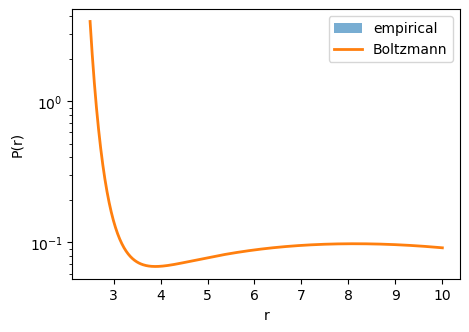

In [91]:
# --- Boltzmann sampling check -----------------------------
burn = int(0.2 * sim.ns)
r_traj = sim.r[burn:, 0, :]                          # shape (n, N)
samples = r_traj.flatten()

# Boltzmann on the whole support
P_full = np.exp(-(U_vals - U_well) / (kB*T_bath))
P_full /= np.trapz(P_full, xs)

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.hist(samples, bins=100, density=True, range=(r_min, p.L), alpha=0.6,
        label="empirical")
ax.plot(xs, P_full, lw=2, label="Boltzmann")
ax.set_yscale('log')
ax.set_xlabel("r"); ax.set_ylabel("P(r)"); ax.legend()

In [109]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_boltzmann_langevin.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_boltzmann_langevin.pdf


#### Kramers exit rate (Langevin)

In [ ]:
# r_traj = sim.r[:, 0, :]
# limit = x_bar
# crossed = r_traj > limit
# first_exit = np.where(crossed.any(0), crossed.argmax(0), len(r_traj))
# mask = np.arange(len(r_traj))[burn:, None] < first_exit[None, :]

In [89]:
first_exit_cum = []
first_entry_cum = []

for i in range(sim.N):
    first_exit_cum = np.concatenate((first_exit_cum, sim.A_intervals[i][1:]))
    first_entry_cum = np.concatenate((first_entry_cum, sim.B_intervals[i][1:]))

empirical rate  k = 1/<T_exit> = nan
Kramers   rate  k             = 0.1091
ratio empirical / Kramers     = nan


/tmp/ipykernel_257284/1303255116.py:9: RuntimeWarning: Mean of empty slice.
  mean_fpt = fpt.mean()
/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: zero-size array to reduction operation maximum which has no identity

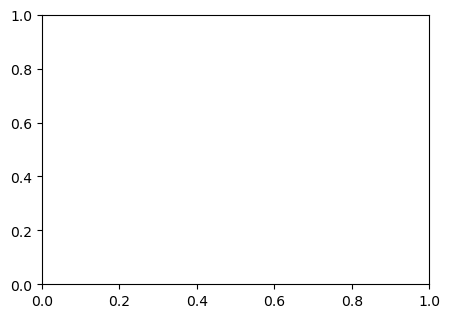

In [90]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] < limit).any(0)
# fpt = first_exit[exited] * sim.dt * sim.nskip
fpt = first_exit_cum * sim.dt
# print(f"{exited.sum()}/{sim.N} trajectories exited")

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 1.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")
# ax.set_xscale("log")

In [115]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_exit_rate_langevin.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_exit_rate_langevin.pdf


#### Distance trace

nsteps:  100000
total physical time:  50.0
bead relaxation time:  0.3333333333333333


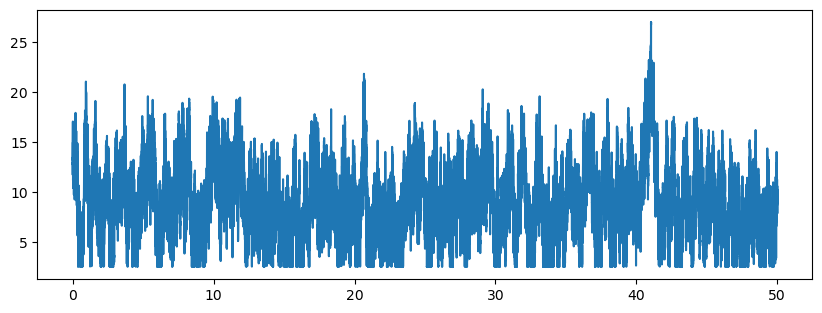

In [11]:
fig, ax = plt.subplots(1,1,figsize=(10, 3.5))

ax.plot(t_grid_distance, distance_traj[1])
print("nsteps: ", nsteps_distance)
print("total physical time: ", dt*nsteps_distance)
print("bead relaxation time: ", _first["bead_relax_time"])
# ax.set_xlim(10, 200)

#### Distance hist

0.0912


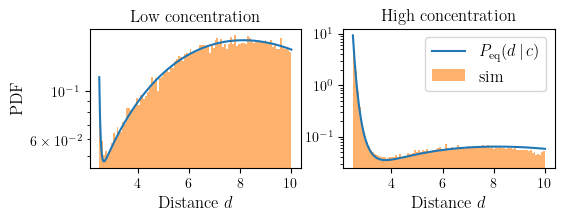

In [495]:
fig, ax = plt.subplots(1,2,figsize=(6.0, 1.8))

keya = 0
b = _first["rouse_params"]["kuhn_length"]
R = _first["surface_params"]["R"]
kBT = _first["rouse_params"]["kBT"]
subsampled = distance_traj[keya]

N = _first["rouse_params"]["N"]

pot = total_potential[keya]
xs2 = np.linspace(p.R, p.L, len(pot))
P_eq = np.exp(-pot/kBT)
P_eq /= np.trapz(P_eq, xs2)

ax[0].plot(xs, P_eq, label="theory")
ax[0].hist(subsampled, density=True, bins=100, range=(p.R, p.L), alpha=0.6, label="sim")
ax[0].set_xlabel(r"Distance $d$", fontsize=12)
ax[0].set_ylabel(r"PDF", fontsize=12)
ax[0].set_yscale('log')
ax[0].set_title("Low concentration")

keya = 9
subsampled = distance_traj[keya]
pot = total_potential[keya]
xs2 = np.linspace(p.R, p.L, len(pot))
P_eq = np.exp(-pot/kBT)
P_eq /= np.trapz(P_eq, xs2)

ax[1].plot(xs, P_eq, label=r"$P_{\rm{eq}}(d\,|\, c)$")
ax[1].hist(subsampled, density=True, bins=100, range=(p.R, p.L), alpha=0.6, label="sim")
ax[1].set_xlabel(r"Distance $d$", fontsize=12)
ax[1].legend(fontsize=12)
ax[1].set_title("High concentration")
ax[1].set_yscale('log')

print(alphas[keya])


In [355]:
_first["surface_params"]

{'chi_b': 2.5,
 'omega_b': -0.5,
 'kappa': 1.0,
 'phi_inf': 0.003,
 'R': 2.5,
 'nb': 1.0}

In [496]:
out_dir = "media/figures/20260727"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_distance_distribution_lowc_hic.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260727/rouse_distance_distribution_lowc_hic.pdf


#### Kramers exit rate (Rouse)

In [18]:
dt = data[alphas[keya]]["rouse_params"]["dt"]
nskip = data[alphas[keya]]["sample_skip"]
kBT = data[alphas[keya]]["rouse_params"]["kBT"]
gamma = data[alphas[keya]]["rouse_params"]["friction"]

T_bath = kBT

dV_R = -F(p.R, *args)
tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kBT)/omega_bar) 
         * np.exp(dU / (kBT)) * (1 - np.exp(-dV_R * (x_bar - p.R)/ (kBT))))
tau   = 500 * tau_K

In [19]:
r_traj = distance_traj[::1]

a = p.R + 0.05
b = x_bar
a_crossings = []
b_crossings = []
ab_intervals = []
ba_intervals = []
in_a = False
in_b = False
entered_a, entered_b, exited_a, exited_b = None, None, None, None

for i, xi in enumerate(r_traj):
    if xi < a and not in_a:
        in_a = True
        entered_a = i
        if exited_b is not None:
            ab_intervals.append(entered_a - exited_b)

    if xi > a and r_traj[i-1] <= a:
        in_a = False
        exited_a = i

    if xi > b and not in_b:
        in_b = True
        entered_b = i
        if exited_a is not None:
            ba_intervals.append(entered_b - exited_a)

    if xi < b and r_traj[i-1] >= b:
        in_b = False
        exited_b = i

first_exit = np.array(ab_intervals)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [20]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] > limit).any(0)
exited = (subsampled > limit).any(0)

fpt = first_exit * dt * nskip * 10
print(f"{exited.sum()}/{1} trajectories exited")

D = (kBT) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")

NameError: name 'limit' is not defined

### Mean-squared displacement

Text(0.5, 1.0, 'single locus')

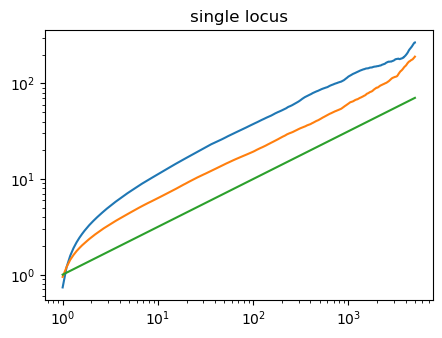

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))
maxlag = dt*len(msd_bead1[0])
msd_time = np.linspace(1, maxlag, len(msd_bead1[0]))
_=ax.plot(msd_time, msd_bead1[0])
_=ax.plot(msd_time, msd_beadMid[0])
ax.plot(msd_time, msd_time**0.5)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title("single locus")

Text(0.5, 1.0, 'two locus')

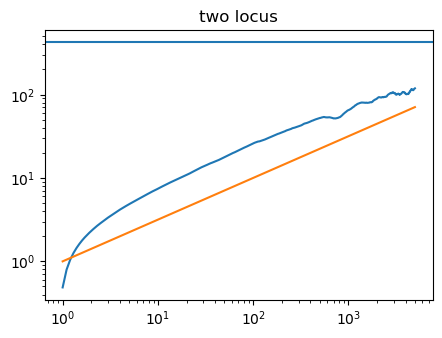

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))
maxlag = dt*len(msd_bead1[0])
msd_time = np.linspace(1, maxlag, len(msd_bead1[0]))
_=ax.plot(msd_time, msd_pairDistance[0])
ax.plot(msd_time, msd_time**0.5)
ax.axhline(y=np.mean(distance_traj**2))
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title("two locus")

### Quick look at Fisher rates

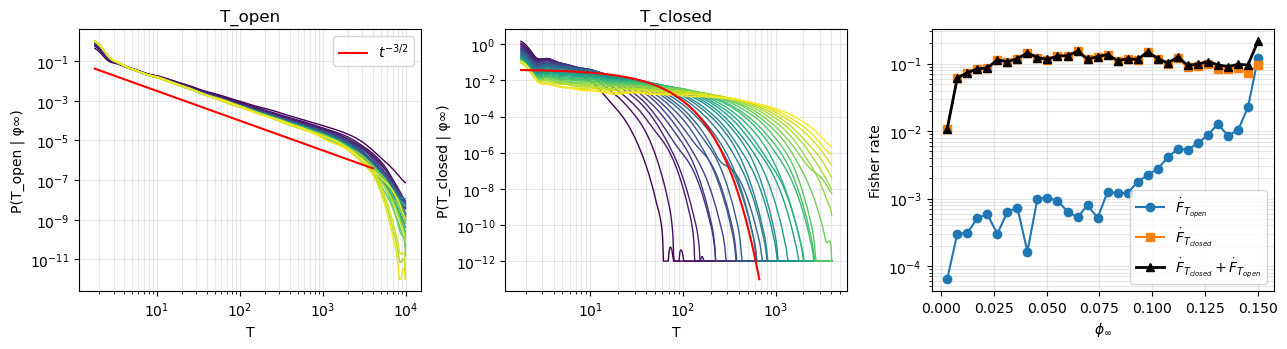

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

PATH = "media/figures/20260528/rouse_mfpt_attractive_fisher_hires.json"

with open(PATH) as f:
    blob = json.load(f)

# scalars / arrays indexed by phi_inf
phi_inf    = np.asarray(blob["phi_inf"], dtype=float)
d_ridge    = np.asarray(blob["d_ridge"], dtype=float)
joint_rate = np.asarray(blob["joint_rate"], dtype=float)

# helper: JSON-encoded arrays may contain `None` where the analysis produced
# a NaN (empty histogram bin, log of 0, etc.). Cast back to NaN for math.
def arr(x):
    return np.asarray(x, dtype=float)   # None -> NaN automatically

def unpack(group):
    return dict(
        T_grid           = arr(group["T_grid"]),            # (n_T,)
        pdfs             = arr(group["pdfs"]),              # (n_phi, n_T)
        mean_T           = arr(group["mean_T"]),            # (n_phi,)
        fisher_per_event = arr(group["fisher_per_event"]),  # (n_phi,) wrt log phi
        fisher_rate      = arr(group["fisher_rate"]),       # (n_phi,) per unit time
    )

open_  = unpack(blob["open"])
closed = unpack(blob["closed"])

# ---- quick sanity plots --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
cmap = plt.get_cmap("viridis")

for name, g in [("T_open", open_), ("T_closed", closed)]:
    ax = axes[0] if name == "T_open" else axes[1]
    for i in range(len(phi_inf)):
        if not np.all(np.isnan(g["pdfs"][i])):
            ax.loglog(g["T_grid"], np.clip(g["pdfs"][i], 1e-12, None),
                      color=cmap(i / max(1, len(phi_inf) - 1)), lw=1.0)
    ax.set_xlabel("T"); ax.set_ylabel(f"P({name} | φ∞)")
    ax.set_title(name); ax.grid(True, which="both", alpha=0.3)

lam = 0.04
stop=int(len(g["T_grid"]) / 1.3)
axes[0].plot(g["T_grid"], g["T_grid"]**(-3/2)*0.1, color="red", label=r"$t^{-3/2}$")
axes[0].legend()
axes[1].plot(g["T_grid"][:stop], lam*np.exp(-g["T_grid"][:stop]*lam), color="red")

ax = axes[2]
ax.plot(phi_inf, open_["fisher_rate"],   "o-", label=r"$\dot F_{T_{open}}$")
ax.plot(phi_inf, closed["fisher_rate"],  "s-", label=r"$\dot F_{T_{closed}}$")
ax.plot(phi_inf, joint_rate,             "^-", color="k", lw=2, label=r"$\dot F_{T_{closed}}+\dot F_{T_{open}}$")
ax.set_xlabel(r"$\phi_\infty$"); ax.set_ylabel("Fisher rate")
ax.set_yscale("log"); ax.legend(); ax.grid(True, which="both", alpha=0.3)

plt.tight_layout(); plt.show()

In [ ]:
out_dir = "media/figures/20260528"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fpt_pdfs_open_close_fisher_rates.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260528/fpt_pdfs_open_close_fisher_rates.pdf


### Fisher rate, Langevin dynamics

#### Load Langevin data

In [431]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "data/20260627/langevin_open_close_exit_at_bar"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _keyas = list(_raw.keys())
    for _keya in _keyas:
        for _run_id, _run in _raw[_keya]["1"].items():
            keya = _run["keya"]
            data[keya] = _run

#### Checking equilibration

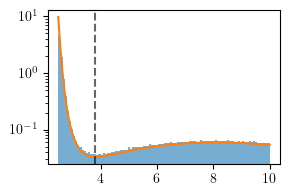

In [458]:
fig, ax = plt.subplots(1,1,figsize=(3, 2))

keya = 30

U_vals      = np.array(data[keya]["total_potential"])
xs          = np.array(data[keya]["pot_grid"])
T_bath      = data[keya]["langevin_params"]["T_bath"]
kB          = data[keya]["langevin_params"]["kB"]
kBT         = kB*T_bath
x_bar       = data[keya]["x_bar"]

P_full = np.exp(-(U_vals) / (kBT))
P_full /= np.trapz(P_full, xs)

bot = np.min(P_full)
height = np.max(P_full)/np.min(P_full)

ax.hist(data[keya]["distance_traj"], density=True, bins=100, 
          range=(xs[0], xs[-1]), alpha=0.6)
ax.plot(xs, P_full)
ax.axvline(x=x_bar, linestyle="dashed", color="black", alpha=0.6)
# ax.text(x_bar-1.14, bot*height**1.1, "closed", fontsize=12)
# ax.text(x_bar+0.4, bot*height**1.1, "open", fontsize=12)
ax.set_yscale("log")

In [26]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "langevin_P_eq_ok_lowc.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/langevin_P_eq_ok_lowc.pdf


#### Checking entry/exit time histograms

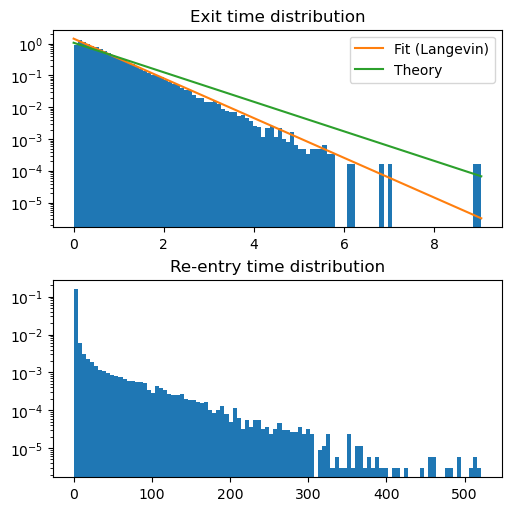

In [42]:
keya = 10

exit_times = data[keya]["exit_times"]
reentry_times = data[keya]["reentry_times"]
k_exit = data[keya]["k_exit"]
k_kramers = 2*data[keya]["k_kramers"]
k_reentry = data[keya]["k_reentry"]

fig, ax = plt.subplots(2,1,figsize=(5, 5), layout="constrained")

exit_grid = np.linspace(0, np.max(exit_times), 100)
ax[0].hist(exit_times, bins=100, density=True)
ax[0].set_yscale('log')
ax[0].plot(exit_grid, k_exit*np.exp(-k_exit*exit_grid), 
           label="Fit (Langevin)")
ax[0].plot(exit_grid, k_kramers*np.exp(-k_kramers*exit_grid),
           label="Theory")
ax[0].set_title("Exit time distribution")
ax[0].legend()

ax[1].set_title("Re-entry time distribution")
entry_grid = np.linspace(0, 300, 100)
ax[1].hist(reentry_times, bins=100, density=True)
ax[1].set_yscale('log')
# ax[1].set_xscale('log')
# ax[1].plot(entry_grid, k_reentry*np.exp(-k_reentry*entry_grid))

In [43]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "exit_reentry_dists.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/exit_reentry_dists.pdf


#### Exit rate and re-entry time

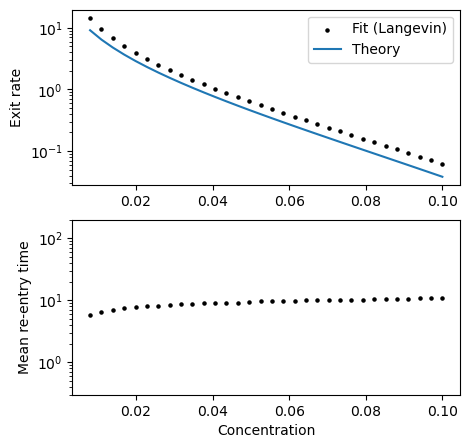

In [48]:
keyas = np.sort(list(data.keys()))

concentrations = np.array([data[keya]["alpha"] for keya in keyas])
k_exit_vals =  np.array([data[keya]["k_exit"] for keya in keyas])
k_kramers_vals =  np.array([data[keya]["k_kramers"] for keya in keyas])
mean_exit_time_vals =  1/k_exit_vals
mean_reentry_time_vals =  np.array([data[keya]["mean_reentry_time"] for keya in keyas])
mean_cycle_time_vals = mean_exit_time_vals + mean_reentry_time_vals

fig, ax = plt.subplots(2,1,figsize=(5, 5))

ax[0].scatter(concentrations, k_exit_vals, s=20, marker=".",c="black", label="Fit (Langevin)")
ax[0].plot(concentrations, 2*k_kramers_vals, label="Theory")
ax[0].set_ylabel("Exit rate")
ax[0].set_yscale("log")
ax[0].legend()

ax[1].scatter(concentrations, mean_reentry_time_vals, s=20, marker=".",c="black")
ax[1].set_ylabel("Mean re-entry time")
ax[1].set_xlabel("Concentration")
ax[1].set_ylim(0.3, 200)
ax[1].set_yscale('log')

In [45]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rates_vs_c.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/rates_vs_c.pdf


#### Local concentration and transcription dynamics

In [3]:
phi_local_vals = np.zeros(len(keyas))
p_closed_vals = np.zeros(len(keyas))

def U(r, *args):
    R, h0, kappa, lam, a, s = args
    profile = np.exp(-lam * (r - R)) * R / r

    return (
        - 2 * np.log(r) + 3 * r ** 2 / (2 * s * a ** 2)
        - 4 * np.pi * R ** 2 * h0 ** 2 * profile / (kappa * (lam + 1 / R))
    )

for k, keya in enumerate(keyas):

    # U_vals      = np.array(data[keya]["total_potential"])
    # xs          = np.array(data[keya]["pot_grid"])
    T_bath      = data[keya]["langevin_params"]["T_bath"]
    kB          = data[keya]["langevin_params"]["kB"]
    kBT         = kB*T_bath
    x_bar       = data[keya]["x_bar"]
    lam         = data[keya]["lam"]
    R           = data[keya]["R"]
    L           = data[keya]["surface_params"]["L"]
    kuhnLength  = data[keya]["rouse_params"]["kuhn_length"]
    beadSep     = data[keya]["rouse_params"]["bead_separation"]
    kappa       = data[keya]["surface_params"]["kappa"]
    omega_b     = data[keya]["surface_params"]["omega_b"]
    phi_inf     = data[keya]["alpha"]
    
    args = (R, omega_b, kappa, lam, kuhnLength, beadSep)
    xs = np.linspace(R, L, 100000)
    U_vals = U(xs, *args)

    P_full = np.exp(-(U_vals) / (kBT))
    P_full /= np.trapz(P_full, xs)

    i_closed = np.where(xs < x_bar)[0]
    p_closed = np.trapz(P_full[i_closed], xs[i_closed])
    p_closed_vals[k] = p_closed

    profile = (phi_inf - omega_b * (np.exp(-lam * (xs - R)) * R / xs) 
                / (kappa * (lam + 1 / R)))
    phi_local_vals[k] = np.trapz(P_full[i_closed]*profile[i_closed]/p_closed, 
                        xs[i_closed])
    
# steady-state transcription model
kb = 1.0
ku = 1.0
tau_on_vals = 1 / (phi_local_vals*kb + k_exit_vals)
tau_off_vals = 1 / (ku + k_exit_vals)
tau_closed_vals = tau_on_vals + tau_off_vals
p_on_vals = p_closed_vals * tau_on_vals / tau_closed_vals
p_off_vals = p_closed_vals * tau_off_vals / tau_closed_vals

p_off_to_open_vals = k_exit_vals / (k_exit_vals + phi_local_vals*kb)
p_on_to_open_vals = k_exit_vals / (k_exit_vals + ku)

fig, ax = plt.subplots(2,1, figsize=(5, 5))

ax[0].plot(concentrations, phi_local_vals)
ax[0].plot(concentrations, concentrations, linestyle="dashed", 
        color="black", alpha=0.6)
ax[0].set_ylabel("Local concentration")
ax[0].set_ylabel("Concentration")

ax[1].plot(concentrations, p_closed_vals)
ax[1].plot(concentrations, mean_exit_time_vals / mean_cycle_time_vals)

NameError: name 'keyas' is not defined

#### Log derivatives and Fisher rate

Text(0.5, 0, 'Concentration')

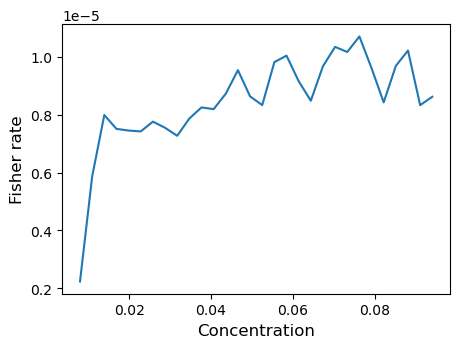

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

# exit rate
k_vals = k_exit_vals
d_exit_vals = np.gradient(k_vals)
d2_exit_vals = np.gradient(np.gradient(k_vals))
d2_log_exit_vals = d2_exit_vals/k_vals - (d_exit_vals/k_vals)**2

# local concentration
d_phi_local_vals = np.gradient(phi_local_vals)
d2_phi_local_vals = np.gradient(np.gradient(phi_local_vals))
d2_log_phi_local_vals = (d2_phi_local_vals/phi_local_vals 
                         - (d_phi_local_vals/phi_local_vals)**2)

# shorthands
c = concentrations
p4 = p_off_vals
p41 = p_off_to_open_vals
p3 = p_on_vals
p31 = p_on_to_open_vals

# fisher rate
fisher_rate_vals = (
    c**2*(d2_exit_vals*p_closed_vals + d2_phi_local_vals*p_off_vals
          -((p4*p41 + p3+p31)*d2_log_exit_vals
            + p4*p41*d2_log_phi_local_vals)/mean_cycle_time_vals)
)

ax.plot(concentrations[:-2], fisher_rate_vals[:-2])
ax.set_ylabel("Fisher rate", fontsize=12)
ax.set_xlabel("Concentration", fontsize=12)

### Fisher rate, Rouse dynamics

#### Take a look at the potentials

In [4]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "/home/tohme/.julia/dev/Droplet/media/figures/"
_data_dir += "20260628/fisher_two_spheres_chi_2.5_h0_-0.5_R_5.0_sweep_c.json"

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
with open(_data_dir, 'r') as _f:
    data = json.load(_f)

U_grids = np.array(data["groups"][0]["U_full_grid"])
d_grid = np.array(data["groups"][0]["d_grid"])

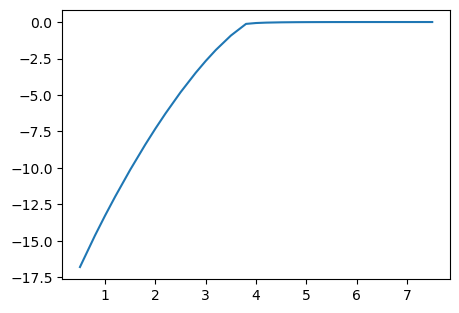

In [5]:
from scipy.interpolate import make_interp_spline

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

key = 30
U_interp = make_interp_spline(
    d_grid[1:], 
    U_grids[key][1:],
    k=5
)

xs = np.linspace(d_grid[0], d_grid[-1], 500)
ax.plot(d_grid, U_grids[key])
# ax.plot(xs, -U_interp(xs), linestyle="dashed")
# ax.set_yscale("log")

#### Load Rouse data

In [319]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "data/20260629/rouse_mfpt_attractive_nonlinear_test"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _keyas = list(_raw.keys())
    for _keya in _keyas:
        for _run_id, _run in _raw[_keya].items():
            data[int(_keya)-1] = _run

keya = 3
r_traj = np.array(data[keya]['distance_traj'])
U_total = np.array(data[keya]['total_potential'])
U_ads = np.array(data[keya]['ads_potential'])
kBT = data[keya]['rouse_params']["kBT"]
R = data[keya]['surface_params']["R"]
L = data[keya]['surface_params']["L"]

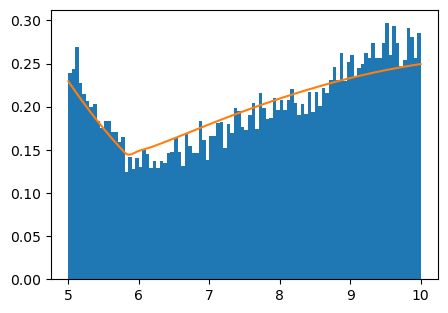

In [320]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

xs = np.linspace(R, L, len(U_total))
P_full = np.exp(-U_total / kBT)
P_full /= np.trapz(P_full, xs)

ax.hist(r_traj, bins=100, density=True, range=(5, 10))
ax.plot(xs, P_full)

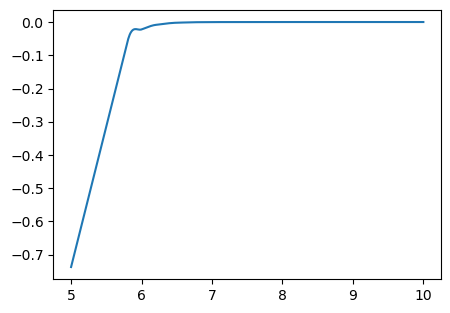

In [321]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))

ax.plot(xs, U_ads)
# ax.plot(d_grid[1:]+R, U_grids[0][1:])


### Two sphere BVP solution

In [14]:
import glob, json, os
import numpy as np

# DATA_DIR = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5"   # <-- point at your sweep's outdir
# DATA_DIR = "data/20260721/test"
# DATA_DIR = "data/20260722/fisher_two_spheres_R_4_h0_-0.5_chi_3"
# DATA_DIR = "data/20260722/fisher_two_spheres_chi_3_h0_-0.5_R_4"
# DATA_DIR = "data/20260724/R_4_h0_-1.0_chi_3/"
# DATA_DIR = "data/20260724/R_4_h0_-1.6_chi_4/"
# DATA_DIR = "data/20260724/R_4_h0_-0.6_chi_2.5/"
# DATA_DIR = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/"
# DATA_DIR = "data/20260724/R_5_h0_-0.6_chi_2.5/"
# DATA_DIR = "data/20260725/R_5_h0_-0.55_chi_2.5/"   # first smooth
# DATA_DIR = "data/20260725/R_5_h0_-0.6_chi_2.5_v2/"
# DATA_DIR = "data/20260727/R_5_h0_-0.9_chi_2.8/"
# DATA_DIR = "data/20260727/R_5_h0_-1.0_chi_3/"
# DATA_DIR = "data/20260728/R_5_h0_-0.4_chi_2.8/"
# DATA_DIR = "data/20260728/R_5_h0_-0.4_chi_2.8_hires/"
DATA_DIR = "data/20260728/R_5_h0_-0.5_chi_2.8/"

def load_fisher(data_dir):
    """Aggregate output_cpu*.json from a fisher_two_spheres sweep into a flat record list."""
    recs = []
    def descend(node):                        # sweep.jl nests as {keya: {keyb: record}}
        if isinstance(node, dict):
            if "phi_inf" in node and "U_full" in node:
                recs.append(node)
            else:
                for v in node.values(): descend(v)
        elif isinstance(node, list):
            for v in node: descend(v)
    files = sorted(glob.glob(os.path.join(data_dir, "output_cpu*.json")))
    assert files, f"no output_cpu*.json under {data_dir}"
    for f in files:
        with open(f) as fh: descend(json.load(fh))
    recs.sort(key=lambda r: (r["omega_b"], r["phi_inf"]))   # phi_inf ascending per omega_b
    return recs

records = load_fisher(DATA_DIR)
print(f"{len(records)} records | params sections:", list(records[0].get("params", {})))

32 records | params sections: ['sim', 'fpt', 'bvp', 'surface', 'sweep', 'rouse']


#### Quick look at the potentials

0.09273573439374971
0.0584833421741228


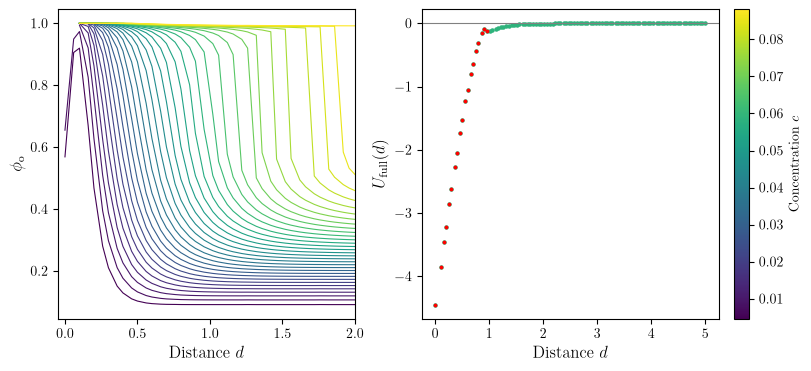

In [105]:
import matplotlib.pyplot as plt
arr = lambda x: np.array(x, dtype=float)      # Julia NaN/null -> np.nan

phi_inf = arr([r["phi_inf"] for r in records])
phi_surf   = arr([r["phi_surf"]   for r in records])
omega_b   = arr([r["omega_b"]   for r in records])
branch = arr([r["branch"]])
print(records[0]["binodal"])

fig, ax = plt.subplots(1, 2, figsize=(8, 3.6), layout="constrained")

j, k = 0, 15
norm = plt.Normalize(vmin=phi_inf.min(), vmax=phi_inf.max())
cmap = mpl.cm.viridis
r = records[k]                          # equilibrium pair potential U_full(d)

for k, r in enumerate(records):
    if k % 1 == 0:
        c = cmap(norm(phi_inf[k]))
        ax[0].plot(arr(r["d_grid"]), r["phi_surf"], lw=0.8, color=c)

ax[0].set_xlabel(r"Distance $d$", fontsize=12)
ax[0].set_ylabel(r"$\phi_{\rm o}$", fontsize=12)
ax[0].set_xlim(-0.05, 2)

for k, r in enumerate(records):
    if k % 1 == 0 and k == 20:
        c = cmap(norm(phi_inf[k]))
        d_grid = arr(r["d_grid"])
        U_full = arr(r["U_full"])
        U_bridged = arr(r["U_bridged"])
        U_unbridged = arr(r["U_unbridged"])
        ax[1].scatter(d_grid, U_full, color=c, s=5)
        ax[1].scatter(d_grid, U_bridged, s=3, color="red")
        # ax[1].scatter(d_grid, U_unbridged, color="blue", s=5)
        # ax[1].plot(d_grid, np.gradient(U_full, d_grid), ms=3)
        print(phi_inf[k])

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax[1], label=r"Concentration $c$")
ax[1].axhline(0, lw=0.8, color="gray")

ax[1].set_xlabel(r"Distance $d$", fontsize=12)
ax[1].set_ylabel(r"$U_{\rm full}(d)$", fontsize=12); 
# ax[1].set_xlim(-0.1, 2.8)
plt.show()
# phi_inf[k]

In [665]:
out_dir = "media/figures/20260728"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "profiles_potentials_2.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260728/profiles_potentials_2.pdf


### Two sphere BVP ($d$-major)

#### Picking Rouse params

In [301]:
ss = [150]
aa = [0.3, 6]
Ds = [3, 60]

for s in ss:
    for a in aa:
        for D in Ds:
            dU = (-2*np.log(D/(2*a*np.sqrt(2*s/3*np.pi)))
                +3*(8*s*a**2/(3*np.pi)-D**2)/(2*s*a**2))
            print("s:", s, "  a:", a, "  R:", D/2, r"  dU:", dU)

s: 150   a: 0.3   R: 1.5   dU: 2.8042637917044533
s: 150   a: 0.3   R: 30.0   dU: -402.1872007554035
s: 150   a: 6   R: 1.5   dU: 9.793228338812435
s: 150   a: 6   R: 30.0   dU: 2.8042637917044533


#### Loading data

In [39]:
import glob, json, os
import numpy as np

# d-major sweep: spec/jobs/20260807/fisher_two_spheres.jl shards over the GAP,
# so there is one record per d (plus one with is_ref=True at the reference gap)
# and each record carries the WHOLE phi_inf axis.
# DATA_DIR = "data/20260807/R_5_h0_-0.5_chi_2.8/"
# DATA_DIR = "data/20260807/fisher_two_spheres_test"
# DATA_DIR = "data/20260807/R_5_h0_-0.8_chi_3.0_bcr_0.04/"
# DATA_DIR = "data/20260807/R_5_h0_-0.5_chi_3.0_bcr_0.04/"
# DATA_DIR = "data/20260807/R_5_h0_-0.6_chi_3.0_bcr_0.05/"
# DATA_DIR = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/"
# DATA_DIR = "data/20260827/test"
# DATA_DIR = "data/20260828/physical_R_20nm"
# DATA_DIR = "data/20260828/test3_hires"   # best candidate so far
# DATA_DIR = "data/20260828/test5"  
# DATA_DIR = "data/20260830/test3"   # best candidate so far
DATA_DIR = "data/20260902/test3"   # best candidate so far

def load_fisher_dmajor(data_dir):
    """Aggregate output_cpu*.json from a d-major arclength sweep into a flat record list."""
    recs = []
    def descend(node):                        # sweep.jl nests as {keya: {keyb: record}}
        if isinstance(node, dict):
            if "F_eq" in node and "d" in node:        # d-major record (was U_full/phi_inf)
                recs.append(node)
            else:
                for v in node.values(): descend(v)
        elif isinstance(node, list):
            for v in node: descend(v)
    files = sorted(glob.glob(os.path.join(data_dir, "output_cpu*.json")))
    assert files, f"no output_cpu*.json under {data_dir}"
    for f in files:
        with open(f) as fh: descend(json.load(fh))
    assert recs, (f"no d-major records under {data_dir} — if this sweep predates "
                  f"spec/jobs/20260807 it is phi_inf-major; use load_fisher instead")
    recs.sort(key=lambda r: (r["omega_b"], r["d"]))          # d ascending per omega_b
    return recs

def as_grids(recs, omega_b=None):
    """-> dict of (n_phi, n_d) arrays: U, F_eq, phi_surf, branch, n_branch (+ per-branch)."""
    nan = lambda x: np.nan if x is None else float(x)        # JSON null (Julia NaN)
    omegas = sorted({r["omega_b"] for r in recs})
    w = omegas[0] if omega_b is None else omega_b
    recs = [r for r in recs if r["omega_b"] == w]

    ref  = [r for r in recs if r.get("is_ref")]
    body = [r for r in recs if not r.get("is_ref")]
    assert ref, ("no is_ref record — sweep.jl dropped the reference gap; "
                 "nparams = n_d + 1 must be divisible by ncpus")
    phi_inf = np.array(recs[0]["phi_inf"], float)                 # (n_phi,)
    d       = np.array([r["d"] for r in body], float)             # (n_d,)
    F_ref   = np.array([nan(v) for v in ref[0]["F_eq"]])          # (n_phi,)
    n_phi, n_d = len(phi_inf), len(d)

    col = lambda k: np.array([[nan(v) for v in r[k]] for r in body]).T   # (n_phi, n_d)
    F_eq = col("F_eq")

    # Per-branch detail, ordered dilute -> dense, so where n_branch == 3 the
    # slots are thin / saddle / bridged.  NaN where that branch doesn't exist.
    nb = max(max(r["n_branch"]) for r in body)
    shape = (n_phi, n_d, nb)
    F_br, gapc_br, surf_br = (np.full(shape, np.nan) for _ in range(3))
    stab_br = np.zeros(shape, bool)
    for j, r in enumerate(body):
        for i in range(n_phi):
            for k in range(len(r["F"][i])):
                F_br[i, j, k]    = nan(r["F"][i][k])
                gapc_br[i, j, k] = nan(r["gap_center"][i][k])
                surf_br[i, j, k] = nan(r["phi_surf_branch"][i][k])
                stab_br[i, j, k] = bool(r["stable"][i][k])

    return dict(
        omega_b=w, phi_inf=phi_inf, d=d, d_ref=ref[0]["d"], binodal=recs[0]["binodal"],
        F_ref=F_ref, F_eq=F_eq,
        U=F_eq - F_ref[:, None],                 # pair potential, (n_phi, n_d)
        phi_surf=col("phi_surf"),                # (n_phi, n_d)
        branch=col("branch_eq").astype(int),     # 1 thin, 3 bridged, 0 none
        n_branch=col("n_branch").astype(int),    # 1 outside the hysteresis window, 3 inside
        U_br=F_br - F_ref[:, None, None],        # (n_phi, n_d, nb)
        gapc_br=gapc_br, surf_br=surf_br, stab_br=stab_br,
        folds={r["d"]: np.array(r["folds"], float) for r in body},
    )

records = load_fisher_dmajor(DATA_DIR)
g = as_grids(records)
U, phi_inf, d = g["U"], g["phi_inf"], g["d"]
print(f"{len(records)} records | omega_b={g['omega_b']} | U {U.shape} = (n_phi, n_d)")
print(f"  phi_inf {phi_inf.min():.5g}..{phi_inf.max():.5g} (binodal {g['binodal']:.5g}), "
      f"d {d.min():.3g}..{d.max():.3g}, d_ref {g['d_ref']:.3g}")
print(f"  bridged at {(g['branch'] == 3).sum()}/{U.size} (phi_inf, d); "
      f"3 branches at {(g['n_branch'] == 3).sum()}; U finite {np.isfinite(U).sum()}/{U.size}")

18 records | omega_b=-0.008 | U (32, 17) = (n_phi, n_d)
  phi_inf 3.2278e-05..0.00030664 (binodal 0.00032278), d 0..64.8, d_ref 260
  bridged at 90/544 (phi_inf, d); 3 branches at 64; U finite 544/544


In [43]:
# [print(k) for k in records[0].keys()]
np.max([records[k]["runtime_min"] for k in range(len(records))])
# records[0]["params"]

np.float64(17.959039183457694)

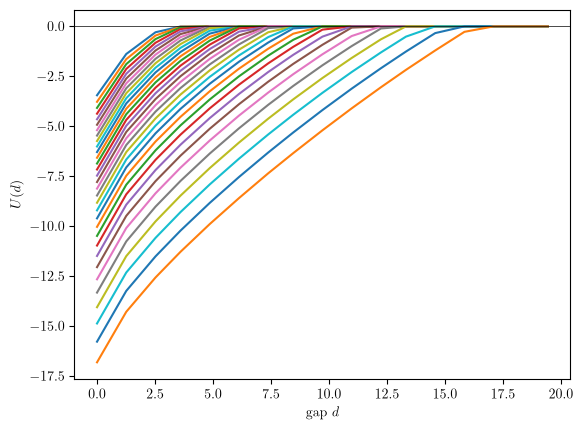

In [41]:
fig, ax = plt.subplots(1,1)

for i in range(0, len(phi_inf), max(1, len(phi_inf) // 32)):
    ax.plot(d*0.3, g["U"][i,:], label=f"$\\phi_\\infty$={phi_inf[i]:.4f}")
    # ax.scatter(d, g["U_br"][i,:,0], label=f"$\\phi_\\infty$={phi_inf[i]:.4f}", s=10)
ax.axhline(0, lw=0.5, c="k"); 
ax.set_xlabel("gap $d$"); 
ax.set_ylabel("$U(d)$"); 
# ax.set_ylim(-7, 0.2)
# ax.set_xlim(-0.1, 2.6)
# ax.legend()

#### Interpolated potentials

In [44]:
import json
import numpy as np

# Same location as PARAMS.sim.output_dir / PARAMS.sim.interp_file
# INTERP_JSON = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260721/test/bvp_potential_interp.json"
# INTERP_JSON = "data/20260722/fisher_two_spheres_chi_3_h0_-0.5_R_4/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-1.0_chi_3/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-0.6_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_5_h0_-0.5_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260725/R_5_h0_-0.55_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260725/bvp_potential_interp.json"   # linear potential
# INTERP_JSON = "data/20260725/R_5_h0_-0.55_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260728/R_5_h0_-0.4_chi_2.8/bvp_potential_interp.json" # fig5 F vs s plot
# INTERP_JSON = "data/20260807/fisher_two_spheres_test/bvp_potential_interp.json"
# INTERP_JSON = "data/20260807/R_5_h0_-0.6_chi_3.0_bcr_0.05/bvp_potential_interp.json"
# INTERP_JSON = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/bvp_potential_interp.json"
# INTERP_JSON = "data/20260827/test/bvp_potential_interp.json"
# INTERP_JSON = "data/20260828/physical_R_20nm/bvp_potential_interp.json"
# INTERP_JSON = "data/20260830/test3/bvp_potential_interp.json"
INTERP_JSON = "data/20260902/test3/bvp_potential_interp.json"

def load_bvp_interp(path=INTERP_JSON):
    """bvp_potential_interp.jl output -> dict of numpy arrays (JSON null -> np.nan)."""
    with open(path) as f:
        d = json.load(f)
    arr = lambda x: np.array(x, dtype=float)
    return {
        "params":           d["params"],                 # full PARAMS tree (incl. sim, fpt, ...)
        "phi_inf":          arr(d["phi_inf"]),            # (nphi,)  == phi_inf_grid(PARAMS)
        "omega_b":          float(d["omega_b"]),
        "R":                float(d["R"]),
        "d_grid":           arr(d["d_grid"]),             # (N_D,)   BVP surface gaps
        "x_grid":           arr(d["x_grid"]),             # (Ngrid,) x = d + R
        "U_full_raw":       arr(d["U_full_raw"]),         # (nphi, N_D)   NaN where BVP unsolved
        "phi_surf_raw":     arr(d["phi_surf_raw"]),       # (nphi, N_D)   gap-facing surface phi
        "U_full_interp":    arr(d["U_full_interp"]),      # (nphi, Ngrid) nonlinear BVP, interpolated
        "phi_surf_interp":  arr(d["phi_surf_interp"]),      # (nphi, Ngrid) nonlinear BVP, interpolated
        "U_linear":         arr(d["U_linear"]),           # (nphi, Ngrid) linear-response U_ads
        "U_tot_full":       arr(d["U_tot_full"]),         # (nphi, Ngrid) + jacobian + Rouse spring
        "U_tot_linear":     arr(d["U_tot_linear"]),       # (nphi, Ngrid) + jacobian + Rouse spring
        # "input_by_cpu":     d["input_by_cpu"],            # {cpu: {phi_inf, U_full, phi_surf, d_grid}}
    }

D = load_bvp_interp()
print({k: (v.shape if isinstance(v, np.ndarray) else type(v).__name__) for k, v in D.items()})
# e.g. index a phi_inf row:  x, U = D["x_grid"], D["U_tot_full"][0]


{'params': 'dict', 'phi_inf': (32,), 'omega_b': 'float', 'R': 'float', 'd_grid': (17,), 'x_grid': (1500,), 'U_full_raw': (32, 17), 'phi_surf_raw': (32, 17), 'U_full_interp': (32, 1500), 'phi_surf_interp': (32, 1500), 'U_linear': (32, 1500), 'U_tot_full': (32, 1500), 'U_tot_linear': (32, 1500)}


In [21]:
D["params"]

{'sim': {'fisher_file': 'fisher_rate_from_fpt_solver.json',
  'ncpus': 0,
  'spec_path': '',
  'interp_file': 'bvp_potential_interp.json',
  'output_dir': 'data/20260830/test3',
  'one_sphere_file': 'demo_bvp_profiles.json'},
 'fpt': {'Ngrid': 1500,
  'Nlocal': 100000,
  'ridge_scan_n': 8000,
  'ridge_scan_max': 200.0,
  'potential': 'bvp'},
 'bvp': {'d_min_factor': 0.0,
  'maxiter': 200,
  'bc_reg': 0.0,
  'Nrho': 200,
  'n_d': 17,
  'dz_target': 0.6,
  'bridge_frac': 0.5,
  'z_buf': 60.0,
  'd_ref_factor': 2.0,
  'f_tol': 1e-06,
  'arc_dlambda0': 0.0,
  'arc_max_steps': 400,
  'd_max_factor': 0.5,
  'rho_max': 360.0},
 'surface': {'eps': 1e-08,
  'parallel_plates': False,
  'chi_b': 0.5280059665030825,
  'omega_b': -0.008,
  'kappa': 5.19,
  'phi_inf': 0.09,
  'L': 100.0,
  'R': 130.0,
  'conserve_volume': False,
  'nb': 4000.0},
 'sweep': {'n_phi': 32,
  'omega_b_values': [-0.008],
  'phi_inf_values': [],
  'phi_frac_min': 0.1,
  'phi_frac_max': 0.95},
 'rouse': {'friction': 1.34770

0.37419354838709673


(38.0, 150.0)

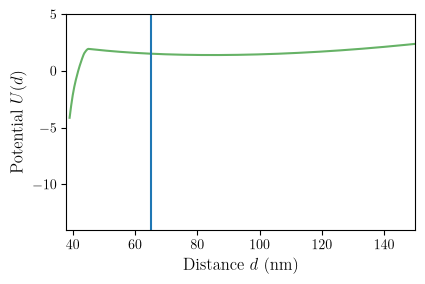

In [85]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1, 1, figsize=(4.5, 2.8))

keya = 10
xend = -1
print(phi_inf[keya]/phi_inf[0]/10)
d_grid = D["x_grid"][:xend]
U_full_interp = D["U_full_interp"].T[:xend, :keya]
U_tot_linear = D["U_tot_linear"].T[:xend, :keya]
U_tot_full = D["U_tot_full"].T[:xend, keya]
F_tot_full = - np.gradient(U_full_interp, d_grid, axis=0)
# _=ax.plot(d_grid, U_tot_linear-2*np.log(d_grid)+3 * d_grid**2 / (2 * s * 1^2))
# _=ax.plot(D["x_grid"][:xend], D["U_tot_linear"].T[:xend, 1], 
#           color="navy", alpha=0.6, label=r"Low $c$")
beta = 1
# _=ax.plot(D["x_grid"][:xend]*0.3, np.exp(-beta*U_tot_full), 
#           color="green", alpha=0.6, label=r"High $c$")
_=ax.plot(D["x_grid"][:xend]*0.3, U_tot_full, 
          color="green", alpha=0.6, label=r"High $c$")
F_tot_linear = - np.gradient(U_tot_linear, d_grid, axis=0)

z = D["x_grid"][:xend]*0.3
Z = np.trapezoid(np.exp(-beta*U_tot_full), z)
ax.axvline(np.trapezoid(z*np.exp(-beta*U_tot_full)/Z, z))
ax.set_ylabel(r"Potential $U(d)$", fontsize=12)
ax.set_xlabel(r"Distance $d$ (nm)", fontsize=12)
ax.set_ylim(-14, 5)
ax.set_xlim(38, 150)
# for x in x_ridge:
#     ax.axvline(x*0.3, alpha=0.2)

# ax.axhline(1.7)
# ax.set_ylim(-6.5, -2.5)
# ax.set_xlim(1.4, 3.5)
# ax.legend(fontsize=12)


In [892]:
out_dir = "media/figures/20260730"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "combined_potential_vs_s.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260730/combined_potential_vs_s.pdf


#### Minimum $s$ per max $c$

Text(0.5, 0, 'Maximum concentration $c$')

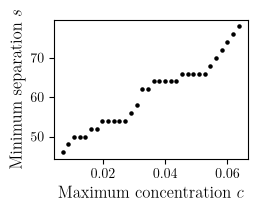

In [649]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

ridges = np.zeros(32)
seps = np.zeros(32)
max_phis = np.zeros(32)
phi_infs = D["phi_inf"]

fig, ax = plt.subplots(1, 1, figsize=(2.5, 1.8))
d_grid = D["x_grid"]

for keya in range(32):
    # scan for the smallest s such that F = dU/dx has a root

    for s in range(5, 300):
        U_ads = D["U_full_interp"].T[:, keya]
        U_tot = (U_ads-2*np.log(d_grid)
                    +3 * d_grid**2 / (2 * s * 1^2))

        F_tot = np.gradient(U_tot, d_grid, axis=0)

        if np.min(F_tot) < 0:
            break

    seps[keya] = s
    ridges[keya] = np.argmin(F_tot)
    max_phis[keya] = phi_infs[keya]

ax.scatter(max_phis, seps, color="black", s=5)

ax.set_ylabel(r"Minimum separation $s$", fontsize=12)
ax.set_xlabel(r"Maximum concentration $c$", fontsize=12)
# ax.set_ylim(-6.5, -2.5)
# ax.set_xlim(4.9, 6.2)

In [650]:
out_dir = "media/figures/20260807"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "min_sep.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260807/min_sep.pdf


### Exact FPT PDFs from solver

In [151]:
import json
import numpy as np

# dirname = "data/20260706/fpt_solver_c_sweep_h0_-0.3/fpt_solver_c_sweep.json"
# dirname = "data/20260718/fpt_solver_c_sweep_bvp/fpt_solver_c_sweep.json"
# dirname = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260722/fisher_two_spheres_R_5_h0_-0.6/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260721/test/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_4_h0_-0.6_chi_2.5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_5_h0_-0.5_chi_2.5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260725/R_5_h0_-0.55_chi_2.5/fisher_rate_from_fpt_solver.json"  # smooth
# dirname = "data/20260725/fisher_rate_from_fpt_solver.json"    # linear potential
# dirname = "data/20260728/R_5_h0_-0.4_chi_2.8_hires/fisher_rate_from_fpt_solver.json"  # smooth
# dirname = "data/20260728/R_5_h0_-0.5_chi_2.8/fisher_rate_from_fpt_solver.json"  # smooth
# dirname = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/fisher_rate_from_fpt_solver.json"  # very smooth
# dirname = "data/20260807/R_5_h0_-0.8_chi_3.0_bcr_0.04/fisher_rate_from_fpt_solver.json"  # very smooth
# dirname = "data/20260830/test3/fisher_rate_from_fpt_solver.json"
dirname = "data/20260902/test3/fisher_rate_from_fpt_solver.json"

with open(dirname) as f:
    d = json.load(f)

phi_infs = np.array(d["phi_infs"])            # swept concentrations (50,)
recs     = d["per_phi"]                        # list of 50 per-concentration records

coef = 50
# stack scalars into arrays indexed by phi
lam               = np.array([r["lam"]         for r in recs])
x_ridge           = np.array([r["x_ridge"]     for r in recs])
barrier           = np.array([r["barrier"]     for r in recs])
well_depth        = np.array([r["well_depth"]  for r in recs])
mfpt_esc          = np.array([r["escape_mfpt"] for r in recs]) * coef
mfpt_ret          = np.array([r["return_mfpt"] for r in recs])* coef
fisher_poly       = np.array([r["fisher"] for r in recs]) #/ coef
fisher_poly_esc   = np.array([r["fisher_esc"] for r in recs]) # / coef
fisher_poly_ret   = np.array([r["fisher_ret"] for r in recs]) # / coef
phi_closed    = np.array([r["phi_local"]   for r in recs])
dphi_closed   = np.array([r["dphi_local"]  for r in recs])
phi_surf_2spheres     = np.array([r["phi_surf"]    for r in recs])
dphi_surf_2spheres    = np.gradient(phi_surf_2spheres[:,0], phi_infs[:-2])

# per-phi curves are ragged only in name; grab one record like this:
r = recs[0]                                    # r["phi_inf"] == phi_infs[0]
x_esc, U_esc = np.array(r["x_grid_esc"]), np.array(r["U_tot_esc"])   # potential (escape grid)
x_ret, U_ret = np.array(r["x_grid_ret"]), np.array(r["U_tot_ret"])   # potential (return grid)
t_esc, pdf_esc = np.array(r["escape_t"]), np.array(r["escape_pdf"])  # escape FPT density
t_ret, pdf_ret = np.array(r["return_t"]), np.array(r["return_pdf"])  # return FPT density

#### FPT distributions

/tmp/ipykernel_14186/3349117095.py:14: RuntimeWarning: invalid value encountered in log
  ax[0].plot(t_esc, np.log(pdf_esc), color=c, alpha=0.5)
/tmp/ipykernel_14186/3349117095.py:21: RuntimeWarning: invalid value encountered in log
  ax[1].plot(t_ret, np.log(pdf_ret), color=c, alpha=0.5)


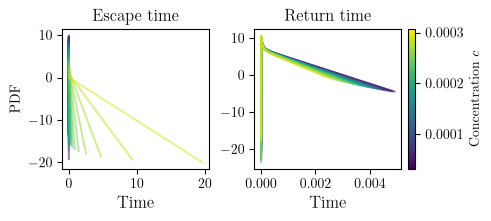

In [47]:
fig, ax = plt.subplots(1,2,figsize=(4.8, 2.1), layout="constrained")

norm = plt.Normalize(vmin=phi_infs.min(), vmax=phi_infs.max())
cmap = mpl.cm.viridis

for k, r in enumerate(recs):  
    c = cmap(norm(phi_infs[k]))
                                      # r["phi_inf"] == phi_infs[0]
    x_esc, U_esc = np.array(r["x_grid_esc"]), np.array(r["U_tot_esc"])   # potential (escape grid)
    x_ret, U_ret = np.array(r["x_grid_ret"]), np.array(r["U_tot_ret"])   # potential (return grid)
    t_esc, pdf_esc = np.array(r["escape_t"]), np.array(r["escape_pdf"])  # escape FPT density
    t_ret, pdf_ret = np.array(r["return_t"]), np.array(r["return_pdf"])  # return FPT density

    ax[0].plot(t_esc, np.log(pdf_esc), color=c, alpha=0.5)
    ax[0].set_title("Escape time")
    ax[0].set_xlabel("Time", fontsize=12)
    # ax[0].set_xscale("log")
    # ax[0].set_ylim(-30, 4)
    ax[0].set_ylabel("PDF")

    ax[1].plot(t_ret, np.log(pdf_ret), color=c, alpha=0.5)
    ax[1].set_title("Return time")
    ax[1].set_xlabel("Time", fontsize=12)
    # ax[1].set_xscale("log")
    # ax[1].set_ylim(-18, 2)
    # ax[1].set_xlim(0, 50)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax[1], label='Concentration $c$')

In [627]:
out_dir = "media/figures/20260807"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "exit_return_pdfs_rouse.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260807/exit_return_pdfs_rouse.pdf


#### Comparison with Rouse simulation

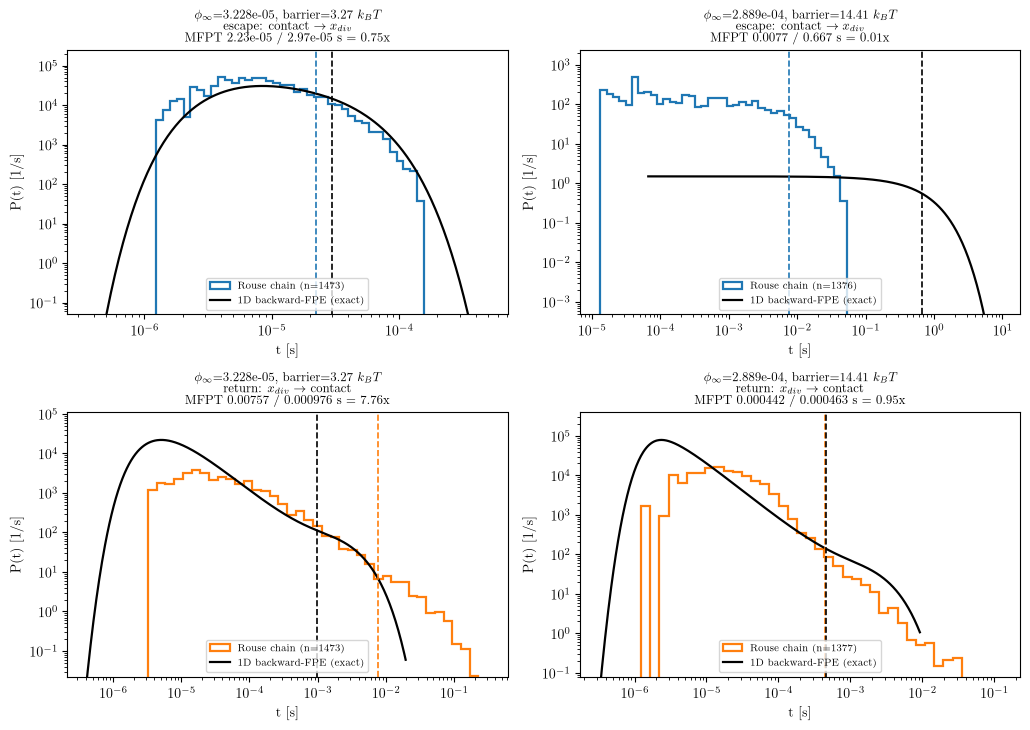

In [115]:
import json, glob
import numpy as np
import matplotlib.pyplot as plt

# --- Rouse sojourn samples (spec/rouse_mfpt_attractive.jl) ------------------
_data_dir = "data/20260830/test3_rouse"
data = {}
for _path in sorted(glob.glob(f"{_data_dir}/output_cpu*.json")):
    with open(_path) as _f:
        _raw = json.load(_f)
    for _keya in _raw:
        for _run in _raw[_keya].values():
            data[_run["alpha"]] = _run

_data_dir = "data/20260830/test3_rouse_run2"
for _path in sorted(glob.glob(f"{_data_dir}/output_cpu*.json")):
    with open(_path) as _f:
        _raw = json.load(_f)
    for _keya in _raw:
        for _run in _raw[_keya].values():
            data[_run["alpha"]] = _run

# --- exact FPT-solver PDFs (fisher_rate_from_fpt_solver.jl) -----------------
_fisher_path = "data/20260830/test3/fisher_rate_from_fpt_solver.json"
with open(_fisher_path) as _f:
    fisher = json.load(_f)
solver = {r["phi_inf"]: r for r in fisher["per_phi"]}

alphas = np.array(sorted(data))
nbins = 40

# Provenance: the chain integrated whatever U_ads was on disk when the sweep
# started, and its thresholds are that run's x_div.  If the pipeline has been
# re-run since, the stored PDFs belong to a different potential -- say so.
for a in [alphas[0], alphas[29]]:
    if not np.isclose(data[a]["x_div"], fisher["x_div"], rtol=1e-9):
        print(f"WARNING phi={a:.4e}: rouse ran at x_div={data[a]['x_div']:.4f}, "
              f"solver json has {fisher['x_div']:.4f} -- potentials differ")

fig, axes = plt.subplots(2, 2, figsize=(5.2 * 2, 7.4),
                         squeeze=False)

for j, a in enumerate([alphas[0], alphas[29]]):
    run = data[a]
    rec = solver[min(solver, key=lambda p: abs(p - a))]
    for i, (key, lab, col) in enumerate([("escape", "escape: contact $\\to x_{div}$", "C0"),
                                         ("return", "return: $x_{div} \\to$ contact", "C1")]):
        ax = axes[i][j]
        t = np.asarray(run[f"{key}_times"])
        t = t[t > 0]
        # log-spaced bins + density=True: the histogram integrates to 1 in t, so it
        # is directly comparable to the solver PDF (both are densities per unit t).
        bins = np.logspace(np.log10(t.min()), np.log10(t.max()), nbins)
        h, _, _ = ax.hist(t, bins=bins, density=True, color=col, histtype="step",
                          lw=1.6, label=f"Rouse chain  (n={t.size})")

        ts, ps = np.asarray(rec[f"{key}_t"]), np.asarray(rec[f"{key}_pdf"])
        ax.plot(ts, ps, "k-", lw=1.6, label="1D backward-FPE (exact)")

        m_r, m_s = t.mean(), rec[f"{key}_mfpt"]
        ax.axvline(m_r, color=col, ls="--", lw=1.2)
        ax.axvline(m_s, color="k", ls="--", lw=1.2)

        ax.set_xscale("log"); ax.set_yscale("log")
        _m = ps > ps.max() * 1e-6                    # trim the solver's dead log-grid head
        ax.set_xlim(min(t.min(), ts[_m][0]) / 2, max(t.max(), ts[_m][-1]) * 2)
        _ymax = max(ps.max(), h.max())
        ax.set_ylim(_ymax * 1e-6, _ymax * 5)
        ax.set_xlabel("t  [s]"); ax.set_ylabel("P(t)  [1/s]")
        ax.set_title(f"$\\phi_\\infty$={a:.3e},  barrier={rec['barrier']:.2f} $k_BT$\n"
                     f"{lab}\nMFPT {m_r:.3g} / {m_s:.3g} s  = {m_r / m_s:.2f}x", fontsize=9)
        ax.legend(fontsize=7, loc="lower center")

fig.tight_layout()

In [48]:
data[alphas[29]]["rouse_params"]

{'bead_separation': 150,
 'dt': 1.1230907457322553e-07,
 'D_eff': 148400000.0,
 'tau_bond': 1.1230907457322553e-05,
 'D_bead': 74200000.0,
 'kuhn_length': 50.0,
 'tau_rouse': 0.025603398831453284,
 't_total': 11.230907457322553,
 'nsteps': 100000000,
 'stiffness': 0.0012,
 'nbeads': 151,
 'friction': 1.3477088948787062e-08,
 'kBT': 1.0}

#### Fisher rate from Rouse simulation

In [152]:
# ---- Fisher information rate from the Rouse sojourn samples ---------------
# Same estimator as the Langevin cell, but fed by spec/jobs/20260828/test3/
# rouse_mfpt_attractive.jl and built to the SAME convention as `fisher_rate_poly`
# (cell 98 / fisher_rate_from_fpt_solver.jl), so the two arrays overlay directly:
#   - score from the OUTER pair (phi_k, phi_k+2) at spacing 2*dphi, weighted by
#     P(t|phi_k)                                     [avg_dlogp2 in the Julia]
#   - prefactor phi_k^2, normalised by the cycle time MFPT_esc + MFPT_ret
#   - divided by `coef`, i.e. reported per ms, exactly like fisher_rate_poly
# Requires `data` from the "Comparison with Rouse simulation" cell.
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ---- controls -------------------------------------------------------------
n_grid       = 500     # points on each fixed log-time grid
smooth_sigma = 20      # CDF smoothing width in grid bins (was 50: over-smooths here)
# coef         = 200    # SAME s -> ms rescale as the solver cell
# ---------------------------------------------------------------------------

phi_rouse = np.array(sorted(data))          # == phi_infs[:-2], uniform spacing
K         = len(phi_rouse)
assert np.allclose(phi_rouse, phi_infs[:len(phi_rouse)], rtol=1e-9), \
    "Rouse phi grid does not match the solver's -- arrays are not comparable"

# pooled series per concentration, in SECONDS.  escape = closed/bound dwell
# (contact -> x_div), return = open/unbound dwell (x_div -> contact).
series_b = [np.asarray(data[a]["escape_times"], float) for a in phi_rouse]
series_u = [np.asarray(data[a]["return_times"], float) for a in phi_rouse]

N_SUB, NBOOT, LOGFIT = 6, 500, True          # N_SUB must match fit_c/fit_o
tr  = np.log10 if LOGFIT else (lambda z: z)
inv = (lambda z: 10.0**z) if LOGFIT else (lambda z: z)

def fit_smooth(x, d, w, lam, n_sub=N_SUB):
    x, d, w = np.asarray(x, float), np.asarray(d, float), np.asarray(w, float)
    N = d.size; n = (N - 1)*n_sub + 1
    t = np.linspace(0.0, 1.0, n); h = t[1] - t[0]
    idx = np.arange(N)*n_sub
    E2 = (np.eye(n, k=1)*-2 + np.eye(n, k=2) + np.eye(n))[:-2]
    S = np.zeros((N, n)); S[np.arange(N), idx] = 1.0
    A = S.T @ (w[:, None]*S)/w.sum() + lam*h*(E2.T @ E2)/h**4
    A += 1e-12*np.trace(A)/n*np.eye(n)
    H = np.linalg.solve(A, S.T*w/w.sum())          # y = H d  (cols of w=0 are 0)
    y = H @ np.where(w > 0, d, 0.0)                # so the nan endpoints can't leak
    return dict(x=x[0] + (x[-1] - x[0])*t, y=y, H=H, idx=idx, lam=lam,
                edf=float(np.trace(H[idx])), w=w,
                valid=(t >= (idx[w > 0][0])/(n - 1)) & (t <= (idx[w > 0][-1])/(n - 1)))

def loocv_smooth(x, d, w, lams, n_sub=N_SUB):
    """Closed-form leave-one-out over the weighted points only."""
    m = np.asarray(w) > 0
    out = []
    for lam in lams:
        f = fit_smooth(x, d, w, lam, n_sub)
        e = (f["y"][f["idx"]] - np.where(m, d, 0.0))/(1.0 - np.diag(f["H"][f["idx"]]))
        out.append((np.mean(e[m]**2), lam, np.where(m, e, 0.0)))
    cv = np.array([o[0] for o in out]); k = int(np.argmin(cv))
    return out[k][1], cv, out[k][2]

def make_grid(all_series, n=n_grid):
    """One fixed log-time grid shared by every concentration (so PDFs line up)."""
    lo = min(a[a > 0].min() for a in all_series)
    hi = max(a.max()        for a in all_series)
    return np.logspace(np.log10(lo), np.log10(hi), n)

def pdf_on_grid(times, grid, sigma=smooth_sigma):
    """Smoothed empirical pdf f(t) evaluated on the *fixed* grid."""
    t = np.sort(np.asarray(times, float)); t = t[t > 0]
    u = np.log10(grid)
    F = np.searchsorted(t, grid, side='right') / t.size    # empirical CDF on grid
    F = gaussian_filter1d(F, sigma=sigma, mode='nearest')  # smooth the CDF
    pdf = np.gradient(F, u) / (grid * np.log(10.0))        # f(t) = dF/dt
    return np.clip(pdf, 0.0, None)

def score2_fisher(t, p_lo, p0, p_hi, dphi):
    """∫ P(t|phi) (∂logP/∂phi)² dt  — score-squared Fisher estimator (central 3-pt in phi)."""
    fl    = p0.max() * 1e-10
    lp_lo = np.log(np.maximum(p_lo, fl))
    lp_hi = np.log(np.maximum(p_hi, fl))
    score = (lp_hi - lp_lo) / (2.0 * dphi)                 # ∂logP/∂phi  (central)
    integrand = p0 * score**2                              # = (∂P/∂phi)² / P
    integrand = np.where((p0 > fl) & (p_lo > fl) & (p_hi > fl), integrand, 0.0)
    return np.trapezoid(integrand, t)                          # = +I(phi), always ≥ 0

# fixed grids + PDF stacks (rows = concentration)
grid_b, grid_u = make_grid(series_b), make_grid(series_u)
P_b = np.array([pdf_on_grid(series_b[k], grid_b) for k in range(K)])
P_u = np.array([pdf_on_grid(series_u[k], grid_u) for k in range(K)])

# cycle time straight from the chain (biased low if a sojourn ran past the trace end)
mfpt_esc_rouse  = np.array([s.mean() for s in series_b])          # seconds
mfpt_ret_rouse  = np.array([s.mean() for s in series_u])
tau_cycle_rouse = mfpt_esc_rouse + mfpt_ret_rouse

# I(phi) with the solver's stencil: p_lo = p0 = P[k], p_hi = P[k+2].  The last two
# entries are NaN -- phi_k+2 is off the end of the Rouse sweep, the same way the
# solver's own fisher_rate is only defined on phi_infs[:-2].
dphi = phi_rouse[1] - phi_rouse[0]
fisher_rate_rouse_esc = np.full(K, np.nan)
fisher_rate_rouse_ret = np.full(K, np.nan)
for k in range(K - 2):
    I_b = score2_fisher(grid_b, P_b[k], P_b[k], P_b[k + 2], dphi)
    I_u = score2_fisher(grid_u, P_u[k], P_u[k], P_u[k + 2], dphi)
    fisher_rate_rouse_esc[k] = phi_rouse[k]**2 * I_b / tau_cycle_rouse[k]
    fisher_rate_rouse_ret[k] = phi_rouse[k]**2 * I_u / tau_cycle_rouse[k]

fisher_rate_rouse     = (fisher_rate_rouse_esc + fisher_rate_rouse_ret) / coef
fisher_rate_rouse_esc = fisher_rate_rouse_esc / coef
fisher_rate_rouse_ret = fisher_rate_rouse_ret / coef
mfpt_esc_rouse        = mfpt_esc_rouse * coef      # ms, as in the solver cell
mfpt_ret_rouse        = mfpt_ret_rouse * coef

In [546]:
K_BATCH  = 10

In [ ]:
# ---- batch (subsampling) variance of the Rouse Fisher rates ----------------
# Cut each concentration's sojourn stream into K_BATCH contiguous batches, run the
# SAME estimator as the plotted curve on every batch -- `pdf_on_grid` exactly as it
# stands, i.e. its own gaussian CDF smoother, no spline on the PDFs -- and measure
# the scatter of the batch values about the full-data curve smoothed along phi with
# the cubic smoothing spline (`fit_smooth` at the LOOCV lambda from `loocv_smooth`):
#
#     batch_var[k] = sum_j (F^(j)[k] - F_spline[k])^2 / (K_BATCH - 1)
#
# Contiguous batches rather than random subsets, so drift along the trajectory would
# show up; the sojourn streams have tau_int ~ 1, so the two are equivalent here.
# `K` above is the number of concentrations, hence the batch count is `K_BATCH`.
#
# READ THE PRINTED TABLE BEFORE USING THE NUMBER.  F^(j) is built from n/K_BATCH
# sojourns, and this estimator's noise-inflation bias grows as the sample shrinks,
# so (i) the batch mean sits ABOVE the full-data value, (ii) centring on F_spline
# makes this bias^2 + variance, not a variance, and (iii) it is the spread of a
# BATCH-sized estimate: the full-data variance is this / K_BATCH, and only while the
# batch mean still tracks F_spline (bias^2/var << 1) is that division meaningful.
lams_phi = np.logspace(-10, 1, 23)          # smoothing range for the phi-direction fit
assert K_BATCH <= min(s.size for s in series_b + series_u), "more batches than sojourns"

def batch_fisher(nbatch):
    """Per-batch Fisher rates, same estimator and units as fisher_rate_rouse_*."""
    sb = [np.array_split(series_b[k], nbatch) for k in range(K)]
    su = [np.array_split(series_u[k], nbatch) for k in range(K)]
    Fb, Fu = np.full((nbatch, K), np.nan), np.full((nbatch, K), np.nan)
    for j in range(nbatch):
        Pb, Pu, tau = np.empty((K, n_grid)), np.empty((K, n_grid)), np.empty(K)
        for k in range(K):
            Pb[k]  = pdf_on_grid(sb[k][j], grid_b)
            Pu[k]  = pdf_on_grid(su[k][j], grid_u)
            tau[k] = sb[k][j].mean() + su[k][j].mean()
        for k in range(K - 2):                  # last two: phi_k+2 is off the sweep
            Fb[j, k] = phi_rouse[k]**2*score2_fisher(grid_b, Pb[k], Pb[k], Pb[k+2], dphi)/tau[k]/coef
            Fu[j, k] = phi_rouse[k]**2*score2_fisher(grid_u, Pu[k], Pu[k], Pu[k+2], dphi)/tau[k]/coef
    return Fb, Fu

def phi_spline(F):
    """Cubic smoothing spline through F(phi), fitted in log10 space at the LOOCV lambda."""
    w = (np.isfinite(F) & (F > 0)).astype(float)
    d = tr(np.where(w > 0, F, 1.0))
    lam, _, _ = loocv_smooth(phi_rouse, d, w, lams_phi)
    f = fit_smooth(phi_rouse, d, w, lam)
    return np.where(w > 0, inv(f["y"][f["idx"]]), np.nan), lam, f["edf"]

F_batch_esc, F_batch_ret = batch_fisher(K_BATCH)
fisher_rate_rouse_esc_fit, lam_esc, edf_esc = phi_spline(fisher_rate_rouse_esc)
fisher_rate_rouse_ret_fit, lam_ret, edf_ret = phi_spline(fisher_rate_rouse_ret)

log_batch_var_rouse_esc = np.sum(
    (np.log10(F_batch_esc) - np.log10(fisher_rate_rouse_esc_fit))**2, axis=0)/(K_BATCH - 1)
log_batch_var_rouse_ret = np.sum(
    (np.log10(F_batch_ret) - np.log10(fisher_rate_rouse_ret_fit))**2, axis=0)/(K_BATCH - 1)

log_batch_var_rouse_esc_fit, _, _ = phi_spline(log_batch_var_rouse_esc)
log_batch_var_rouse_ret_fit, _, _ = phi_spline(log_batch_var_rouse_esc)

# ---- diagnostics ----------------------------------------------------------
v = slice(0, K - 2)                              # the phis where the stencil exists
print(f"phi-spline: esc lam={lam_esc:.0e} edf={edf_esc:.1f}/{K-2}   "
      f"ret lam={lam_ret:.0e} edf={edf_ret:.1f}/{K-2}   (edf ~ K-2 => interpolating)")
for nm, Fj, fit in (("esc", F_batch_esc, fisher_rate_rouse_esc_fit),
                    ("ret", F_batch_ret, fisher_rate_rouse_ret_fit)):
    print(f"sqrt(batch_var)/F_spline  {nm}: " + " ".join(f"{x:.2f}" for x in
          (np.sqrt(np.sum((Fj - fit)**2, axis=0)/(K_BATCH - 1))/fit)[v]))

print(f"\nhow the batch estimator drifts with batch size (median over phi):\n"
      f"{'K_BATCH':>7} {'n/batch':>8} | {'esc <F_j>/F_spl':>16} {'sd_j/F_spl':>11} {'bias^2/var':>11}"
      f" | {'ret <F_j>/F_spl':>16} {'sd_j/F_spl':>11} {'bias^2/var':>11}")
ok = {"esc": [], "ret": []}
for nb_ in sorted({4, 8, 16, 32, K_BATCH}):
    Fb_, Fu_ = batch_fisher(nb_)
    row = [f"{nb_:>7} {int(np.median([s.size for s in series_b]))//nb_:>8} |"]
    for nm, Fj, fit in (("esc", Fb_, fisher_rate_rouse_esc_fit), ("ret", Fu_, fisher_rate_rouse_ret_fit)):
        m, sd = Fj[:, v].mean(0), Fj[:, v].std(0, ddof=1)   # batch mean and true spread
        infl  = np.median(m/fit[v])                          # small-sample inflation
        ok[nm].append(nb_ if infl < 1.25 else 0)
        row.append(f"{infl:>16.2f} {np.median(sd/fit[v]):>11.2f}"
                   f" {np.median((m - fit[v])**2/sd**2):>11.2f}")
    print(" ".join(row))
print("largest scanned K_BATCH whose batch mean still tracks F_spline to 25%:  "
      + "   ".join(f"{nm} <= {max(w) if max(w) else 'none (< 4)'}" for nm, w in ok.items()))

phi-spline: esc lam=3e-07 edf=15.2/28   ret lam=1e-05 edf=7.1/28   (edf ~ K-2 => interpolating)
sqrt(batch_var)/F_spline  esc: 12.63 7.74 3.97 3.68 1.87 2.41 1.03 1.47 0.70 0.65 0.64 0.50 0.50 0.74 0.40 0.37 0.27 0.47 0.32 0.26 0.29 0.17 0.28 0.38 0.47 0.49 0.63 0.82
sqrt(batch_var)/F_spline  ret: 6.68 7.17 4.11 4.94 2.36 3.47 2.01 2.63 2.83 1.36 1.72 1.88 1.21 2.19 1.58 1.64 1.98 3.21 2.76 1.90 3.61 3.84 6.65 6.88 16.68 20.46 41.30 32.26

how the batch estimator drifts with batch size (median over phi):
K_BATCH  n/batch |  esc <F_j>/F_spl  sd_j/F_spl  bias^2/var |  ret <F_j>/F_spl  sd_j/F_spl  bias^2/var
      4     1129 |             1.08        0.25        0.16             1.66        0.78        0.73
      8      564 |             1.21        0.42        0.33             2.50        1.48        1.34
     10      451 |             1.25        0.49        0.29             3.23        2.04        1.26
     16      282 |             1.39        0.72        0.48             4.34        

: 

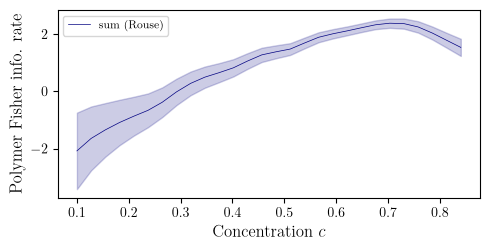

In [ ]:
# ---- plot -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 2.6))
# ax.plot(phi_rouse, fisher_rate_rouse_esc, '-', color='crimson', label='closed (Rouse)')
# ax.plot(phi_rouse, fisher_rate_rouse_ret, '-', color='green',   label='open (Rouse)')

fisher_rouse_logfit = np.log10(fisher_rate_rouse_esc_fit)
fisher_rouse_err_logfit = np.sqrt(log_batch_var_rouse_esc_fit + log_batch_var_rouse_ret_fit)
ax.plot(phi_rouse/binodal[0], fisher_rouse_logfit,'-', color='navy', lw=0.5,    label='sum (Rouse)')
# ax.plot(phi_infs[:-2], fisher_rate_poly, linestyle="dashed", color="black",
#         label=r"$\dot{\mathcal{F}}(c)$  1D backward-FPE")
ax.fill_between(phi_rouse/binodal[0], 
    fisher_rouse_logfit - fisher_rouse_err_logfit, 
    fisher_rouse_logfit + fisher_rouse_err_logfit, color='navy', alpha=0.2)
# ax.fill_between(phi_rouse, fisher_rate_rouse_ret - np.sqrt(batch_var_rouse_ret), 
#                 fisher_rate_rouse_ret + np.sqrt(batch_var_rouse_ret), color='green', alpha=0.2)
ax.set_xlabel(r"Concentration  $c$", fontsize=12)
ax.set_ylabel(r"Polymer Fisher info. rate", fontsize=12)
ax.legend(fontsize=8)
# ax.set_yscale('log')
plt.tight_layout()
plt.show()

#### Polymer Fisher rates

In [162]:
bds1 = (0.18, 0.69, 0.22, 0.22)
bds2 = (0.14, 0.65, 0.25, 0.28)
lloc = (0.8, 0.1)

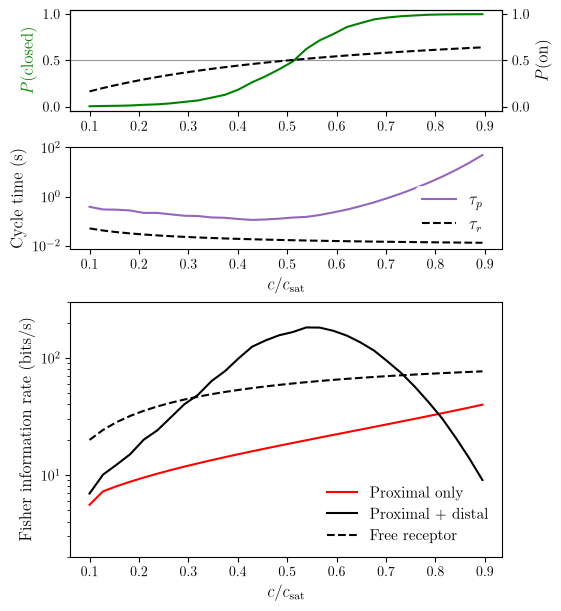

In [170]:
#### load single sphere data

# path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
# path = "data/20260830/test3/demo_bvp_profiles.json"
path = "data/20260902/test3/demo_bvp_profiles.json"
d = json.load(open(path))
phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
mu_inf  = np.array(d["mu_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
h0 = d["params"]["surface"]["omega_b"]
binodal = d["binodal"]
chi = d["chi"]

#### Free receptor

v_tf = 120      # 120 <-> nb = 4000
a = 3e-3        # um / 10 bp
D_tf = 7.4      # um^2/s
kb = 4*a*D_tf   # um^3/s
K_D_frac = 0.5
K_D = K_D_frac*to_nM(binodal[0], v_tf)*1e-24*6.022e23
ku = kb*K_D
c_inf = to_nM(phi_inf, v_tf)*1e-24*6.022e23   # particles / um^3

tau_free = 1 / (kb*c_inf) + 1 / ku
p_free_undersat = kb*c_inf / (kb*c_inf + ku)
fisher_rate_free = 1 / tau_free

#### Poly

# Equilibrium open/closed probabilities

# ---- equilibrium open/closed probabilities from the 1D potential -----------
# Boltzmann weights on the interpolated potential D["U_tot_full"] (which already
# carries the radial jacobian and the Rouse spring, so exp(-beta U) dx is the
# correct measure in x = d + R).  The ridge x_ridge[i] (from the FPT-solver json,
# defined on phi_infs[:-2]) splits the two basins:
#     x < x_ridge  ->  the two spheres are in contact       = CLOSED
#     x > x_ridge  ->  the chain end has left the contact   = OPEN
beta = 1.0

x_bvp   = D["x_grid"]                       # (Ngrid,)
U_bvp   = D["U_tot_full"]                   # (nphi, Ngrid)
n_ridge = len(x_ridge)                      # == len(phi_infs) - 2

assert np.allclose(D["phi_inf"][:n_ridge], phi_infs[:n_ridge], rtol=1e-9), \
    "bvp_potential_interp and fisher_rate_from_fpt_solver were run on different phi grids"

# p_open   = np.full(n_ridge, np.nan)
# p_closed = np.full(n_ridge, np.nan)

# for i in range(n_ridge):
#     U = U_bvp[i]
#     m = np.isfinite(U)                      # drop unsolved BVP points
#     x, w = x_bvp[m], np.exp(-beta * (U[m] - np.nanmin(U[m])))   # shift for stability

#     lo = x <= x_ridge[i]
#     # integrate the closed basin up to the ridge, including the partial last panel
#     Z_closed = np.trapezoid(w[lo], x[lo])
#     if lo.sum() < w.size:                   # linear piece from x[lo][-1] to x_ridge
#         xa, xb = x[lo][-1], x[~lo][0]
#         wr = w[lo][-1] + (w[~lo][0] - w[lo][-1]) * (x_ridge[i] - xa) / (xb - xa)
#         Z_closed += 0.5 * (w[lo][-1] + wr) * (x_ridge[i] - xa)
#     Z = np.trapezoid(w, x)

#     p_closed[i] = Z_closed / Z
#     p_open[i]   = 1.0 - p_closed[i]

tau_poly = mfpt_esc + mfpt_ret_rouse
# mfpt_ret_rouse2 = tau_poly - mfpt_esc
fisher_rate_poly = fisher_poly / tau_poly
p_closed = mfpt_esc / tau_poly
p_open = 1 - p_closed

#### Local

phi_open = phi_full.T[0,:]
c_open = to_nM(phi_open, v_tf)*1e-24*6.022e23
c_closed = to_nM(phi_closed, v_tf)*1e-24*6.022e23
tau_open = 1 / (kb*c_open) + 1 / ku
tau_closed = 1 / (kb*c_closed) + 1 / ku
dphi_open = np.gradient(phi_open, phi_inf)
phi_open_gain = (dphi_open * phi_inf / phi_open) ** 2
phi_closed_gain = (dphi_closed * phi_inf[:-2] / phi_closed) ** 2

fisher_rate_open = phi_open_gain / tau_open
fisher_rate_closed = phi_closed_gain / tau_closed
fisher_rate_local = p_open*fisher_rate_open[:-2] + p_closed*fisher_rate_closed
fisher_local_saved = fisher_rate_local

#### Plot

fig, ax = plt.subplots(3,1,figsize=(5.5, 6),
        gridspec_kw={"height_ratios": [1, 1, 2.5]}, layout="constrained")

ax0 = ax[0].twinx()
ax[0].plot(phi_inf[:-2]/binodal[0], p_closed, color="green")
ax0.plot(phi_inf[:-2]/binodal[0], p_free_undersat[:-2], linestyle="dashed", color="black")
ax0.set_ylabel(r"$P(\rm on)$", color="black", fontsize=12)
# insticks = np.array([0.0, 0.5, 1.0])
ax0.set_ylim(-0.05, 1.05)

ax[0].axhline(0.5, lw=0.8, color="black", alpha=0.4)
ax[0].set_ylabel(r"$P(\rm closed)$", fontsize=12, color="green")
# ax[0].legend(loc="center left", fontsize=12, edgecolor="none")
insticks = np.array([0.0, 0.5, 1.0])
ax[0].set_ylim(-0.05, 1.05)
ax[0].set_yticks(insticks)
ax[0].set_yticklabels(insticks)
xticks = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
ax[0].set_xticks(xticks)
ax[0].set_xticklabels(xticks)
ax[0].set_xlim()

ax[2].plot(phi_inf[:-2]/binodal[0], fisher_rate_open[:-2], color="red", label="Proximal only")

#### Rouse
# ax[2].plot(phi_inf[:-2]/binodal[0], 
#               10**(fisher_rouse_logfit) + fisher_rate_local,
#               label="Proximal + distal", color="black")
# ax[2].fill_between(phi_rouse/binodal[0], 
#     10**(fisher_rouse_logfit - fisher_rouse_err_logfit) + fisher_rate_local, 
#     10**(fisher_rouse_logfit + fisher_rouse_err_logfit) + fisher_rate_local, color='black', alpha=0.2)

#### Langevin
ax[2].plot(phi_inf[:-2]/binodal[0], 
              fisher_rate_poly + fisher_rate_local,
              label="Proximal + distal", color="black")

ax[2].plot(phi_inf[:-2]/binodal[0], fisher_rate_free[:-2], color="black", linestyle="dashed",
           label=r"Free receptor")
ax[2].set_ylim(2, 3e2)
ax[2].set_yscale("log")
ax[2].set_ylabel("Fisher information rate (bits/s)", fontsize=12)
ax[2].legend(fontsize=11, loc="lower right", edgecolor="none")
ax[2].set_xlabel(r"$c/c_{\rm sat}$", fontsize=12)
ax[2].set_xticks(xticks)
ax[2].set_xticklabels(xticks)

# ins = ax[2].inset_axes(bounds = bds1)
ax[1].plot(phi_inf[:-2]/binodal[0], tau_poly, color="C4", label=r"$\tau_{p}$")
ax[1].plot(phi_inf[:-2]/binodal[0], tau_free[:-2], linestyle="dashed", 
         color="black", label=r"$\tau_{r}$")
ax[1].legend(loc=lloc, fontsize=12, edgecolor="none")
ax[1].set_ylim(7e-3, 100)
ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)
ax[1].set_ylabel("Cycle time (s)", fontsize=12)
ax[1].set_xlabel(r"$c/c_{\rm sat}$", fontsize=12)
ax[1].set_yscale('log')

In [171]:
out_dir = "media/figures/20260904"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "allFs_1KD_errbars.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260904/allFs_1KD_errbars.pdf


#### Local Fisher rates

Text(0.5, 0, 'Concentration $c$')

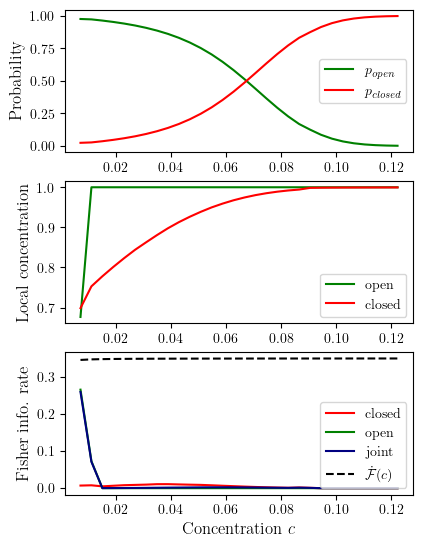

In [446]:
fig, ax = plt.subplots(3,1,figsize=(4.5, 6.3))

p_closed = mfpt_esc / (mfpt_esc + mfpt_ret)
p_open = mfpt_ret / (mfpt_esc + mfpt_ret)

# a = 1        # um
# D_tf = 1      # um^2/s
# kb = 4*a*D_tf 
# ku = 5e-1
# tau_base = 1 / (kb*phi_infs[:-2]) + 1 / ku

tau_closed = 1 / (kb*phi_local_vals) + 1 / ku
tau_open = 1 / (kb*phi_surf_vals[:,0]) + 1 / ku
phi_local_gain = (dphi_local_vals * phi_infs[0:-2] / phi_local_vals) ** 2
phi_surf_gain = (dphi_surf_vals * phi_infs[0:-2] / phi_surf_vals[:,0]) ** 2

fisher_rate_closed = phi_local_gain / tau_closed
fisher_rate_open = phi_surf_gain / tau_open
fisher_rate_base = 1 / tau_base

K = 1
fisher_rate_total = (
    fisher_rate*K + p_closed*fisher_rate_closed + p_open*fisher_rate_open
)

ax[0].plot(phi_infs[:-2], p_open, label=r"$p_{open}$", color="green")
ax[0].plot(phi_infs[:-2], p_closed, label=r"$p_{closed}$", color="red")
ax[0].legend()
# ax[0].set_title(r"$D_{TF} = 100D_{enhancer}$")
ax[0].set_ylabel("Probability", fontsize=12)

ax[1].plot(phi_infs[:-2], phi_surf_vals[:,0], color="green", label="open")
ax[1].plot(phi_infs[:-2], phi_local_vals, color="red", label="closed")
# ax[1].plot(phi_infs[:-2], p_closed*phi_local_vals+p_open*phi_surf_vals[:,0], 
#            color="navy", label="joint")
ax[1].set_ylabel("Local concentration", fontsize=12)
# ax[1].set_yscale('log')
# ax[1].set_xscale('log')
ax[1].legend()

# ax[2].plot(phi_infs[0:-2], fisher_rate*K, 
#         label=r"$\dot{F}_{poly}$", color="green")
ax[2].plot(phi_infs[0:-2], fisher_rate_closed, label=r"closed", color="red")
ax[2].plot(phi_infs[0:-2], fisher_rate_open, label=r"open", color="green")
ax[2].plot(phi_infs[0:-2], p_closed*fisher_rate_closed+p_open*fisher_rate_open, 
        label=r"joint", color="navy")
ax[2].plot(phi_infs[:-2], fisher_rate_base, color="black", linestyle="dashed",
           label=r"$\dot{\mathcal{F}}(c)$")
# ax[2].plot(phi_infs[0:-2], fisher_rate_total, 
#         label=r"$\dot{F}_{total}$", color="black", alpha=0.4)
# ax[1].plot(phi_infs[0:-2], fisher_rate_2)
# ax[2].set_yscale("log")
ax[2].set_ylabel("Fisher info. rate", fontsize=12)
ax[2].legend(fontsize=10, loc="lower right")
ax[2].set_xlabel("Concentration $c$", fontsize=12)
# ax[2].set_ylim(-0.5, 3)

In [73]:
out_dir = "media/figures/20260726"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "F_local_linear_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260726/F_local_linear_potential.pdf


### Fisher rate versus genomic separation

/tmp/ipykernel_196531/2812038105.py:130: UserWarning: The figure layout has changed to tight
  fig.tight_layout();


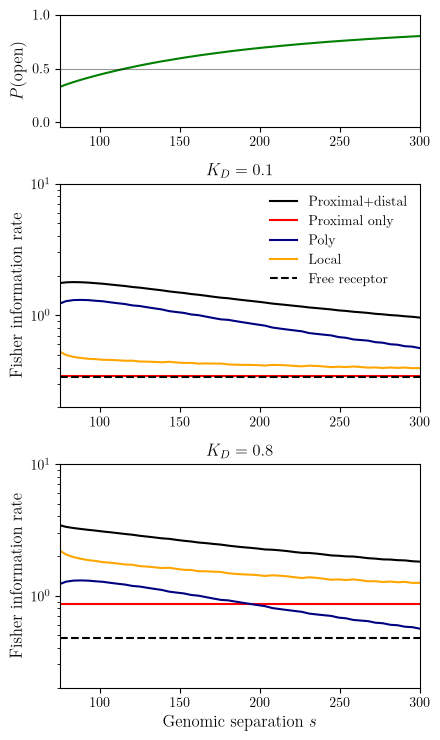

In [535]:
import json
import numpy as np
import matplotlib.pyplot as plt

# path = "data/20260726/fisher_vs_rouse_s.json"
# path = "data/20260727/R_5_h0_-0.55_chi_2.5/fisher_vs_rouse_s.json"
path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04_clone/fisher_vs_rouse_s.json"
d = json.load(open(path))

runs = sorted(d["runs"], key=lambda r: r["s"])          # ascending in s
s    = np.array([r["s"] for r in runs])
phi_infs  = np.array(runs[0]["phi_infs"])                     # concentration grid (same every run)
mfpt_esc             = np.array([r["escape_mfpt"] for r in runs])
mfpt_ret             = np.array([r["return_mfpt"] for r in runs])
fisher_rate_poly     = np.array([r["fisher_rate"] for r in runs])
fisher_rate_poly_esc = np.array([r["fisher_rate_esc"] for r in runs])
fisher_rate_poly_ret = np.array([r["fisher_rate_ret"] for r in runs])
phi_closed           = np.array([r["phi_local"]   for r in runs])
dphi_closed          = np.array([r["dphi_local"]  for r in runs])

### Single sphere data

path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04_clone/demo_bvp_profiles.json"
d = json.load(open(path))
phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)

# each is (n_s, n_phi); n_phi = # of concentration points in phi_inf_values minus 2
f   = lambda key: np.array([[np.nan if v is None else v for v in r[key]] for r in runs])
fisher, esc, ret = f("fisher_rate"), f("fisher_rate_esc"), f("fisher_rate_ret")

#### Free receptor

# a = 3e-3        # um
# D_tf = 7.4      # um^2/s
# kb = 4*a*D_tf 
kb = 10
K_D = 0.8
ku = kb*K_D
tau_free = 1 / (kb*phi_infs) + 1 / ku
fisher_rate_free = 1 / tau_free

#### Poly

tau_poly = (mfpt_esc + mfpt_ret)
fisher_per_cycle = fisher_rate_poly * tau_poly
p_closed = mfpt_esc / (mfpt_esc + mfpt_ret)
p_open = mfpt_ret / (mfpt_esc + mfpt_ret)

#### Local

phi_open = phi_full.T[0,24]
tau_open = 1 / (kb*phi_open) + 1 / ku
tau_closed = 1 / (kb*phi_closed) + 1 / ku
dphi_open = np.gradient(phi_full[:,0], phi_inf)
phi_open_gain = (dphi_open * phi_inf / phi_open) ** 2
phi_closed_gain = (dphi_closed * phi_infs / phi_closed) ** 2

fisher_rate_open = phi_open_gain / tau_open
fisher_rate_closed = phi_closed_gain / tau_closed
fisher_rate_local = p_open*fisher_rate_open[24] + p_closed*fisher_rate_closed
fisher_local_saved = fisher_rate_local

j = 0                                                     # concentration column to plot (phi[j])
fig, ax = plt.subplots(3,1,figsize=(4.5, 7.5),
        gridspec_kw={"height_ratios": [1, 2., 2.]}, layout="constrained")
ax[0].plot(s, p_open, color="green")
# ax[0].plot(s, p_closed, color="red", label="closed")
ax[0].set_ylabel(r"$P(\rm open)$", fontsize=12)
# ax[0].legend(loc="center right", fontsize=10)
ax[0].axhline(0.5, lw=0.8, color="black", alpha=0.4)
insticks = np.array([0.0, 0.5, 1.0])
ax[0].set_yticks(insticks)
ax[0].set_yticklabels(insticks)

ax[2].plot(s, fisher_rate_local[:,0]+fisher[:, j],  
        color="black", label="Proximal+distal")
ax[2].plot(s, fisher_rate_open[24]*np.ones(64),  label=r"Proximal only", color="red")
ax[2].plot(s, fisher[:, j],  
        label=r"Poly", color="navy")
ax[2].plot(s, fisher_rate_local,  
        label=r"Local", color="orange")
ax[2].set_ylabel("Fisher information rate", fontsize=12)
ax[2].set_title(rf"$K_D = {K_D}$")
ax[2].set_ylim(2e-1, 10)
ax[2].set_yscale('log')
ax[2].axhline(1/tau_free, linestyle="dashed", color="black", label="Free receptor")
# ax[2].legend(fontsize=10.0, loc="upper right", edgecolor="none");

K_D = 0.1
ku = kb*K_D
tau_free = 1 / (kb*phi_infs) + 1 / ku
fisher_rate_free = 1 / tau_free

#### Poly

tau_poly = (mfpt_esc + mfpt_ret)
fisher_per_cycle = fisher_rate_poly * tau_poly
p_closed = mfpt_esc / (mfpt_esc + mfpt_ret)
p_open = mfpt_ret / (mfpt_esc + mfpt_ret)

#### Local

phi_open = phi_full.T[0,24]
tau_open = 1 / (kb*phi_open) + 1 / ku
tau_closed = 1 / (kb*phi_closed) + 1 / ku
dphi_open = np.gradient(phi_full[:,0], phi_inf)
phi_open_gain = (dphi_open * phi_inf / phi_open) ** 2
phi_closed_gain = (dphi_closed * phi_infs / phi_closed) ** 2

fisher_rate_open = phi_open_gain / tau_open
fisher_rate_closed = phi_closed_gain / tau_closed
fisher_rate_local = p_open*fisher_rate_open[24] + p_closed*fisher_rate_closed
fisher_local_saved = fisher_rate_local

ax[1].plot(s, fisher_rate_local[:,0]+fisher[:, j], color="black", label="Proximal+distal")
ax[1].plot(s, fisher_rate_open[24]*np.ones(64),  label=r"Proximal only", color="red")
ax[1].plot(s, fisher[:, j],  label=r"Poly", color="navy")
ax[1].plot(s, fisher_rate_local,  label=r"Local", color="orange")
ax[2].set_xlabel("Genomic separation $s$", fontsize=12)
ax[1].set_ylabel("Fisher information rate", fontsize=12)
ax[1].set_title(rf"$K_D = {K_D}$")
ax[1].set_ylim(2e-1, 10)
ax[1].set_yscale('log')
ax[1].axhline(1/tau_free, linestyle="dashed", color="black", label="Free receptor")
ax[1].legend(fontsize=10.0, loc="upper right", edgecolor="none"); 

ax[0].set_xlim(75, 300)
ax[2].set_xlim(75, 300)
ax[1].set_xlim(75, 300)
fig.tight_layout(); 
plt.show()

In [525]:
out_dir = "media/figures/20260831"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fisher_vs_s.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260831/fisher_vs_s.pdf


### Flory Huggins energy density, grand potential

In [132]:
import numdifftools as nd
from scipy import optimize as opt

###### Define basic functions

# Flory-Huggins free energy
def F(phi, *args):
    mu, chi, T, nb, c0 = args
    return mu*phi/nb + T*c0*(chi*phi*(1-phi) + phi*np.log(phi)/nb + (1-phi)*np.log(1-phi))

# Difference between F and tangent
def G(phi, *args):
    mu, chi, T, m, b = args
    return F(phi, mu, chi, T) - m*phi - b

# Its derivative
dG = nd.Derivative(G)

# Positive part of difference between line and curve
def fun(m, b, fvals, phis, beta):
    line = phis * m + b
    overshoot = (np.abs(line - fvals) + (line - fvals)) / 2

    return np.sum(line) - beta * np.sum(overshoot)

def loss(x, *args):
    m, b = x
    fvals = F(phis, *args)

    return  - fun(m, b, fvals, phis, 100)


###### Maximize area under a line, with a hard penalty on going over the F curve

# Find the tangent points: zeros of the diff's derivative
def solve_fh(phis, mu, chi, T, nb):
    x0 = [-1, 0]
    res = opt.minimize(loss, x0, args=(mu,chi,T), method='Nelder-Mead', tol=1e-6)
    m, b = res.x

    # Evaluate it pointwise on the grid of phi values
    dGvals = np.array([dG(p, mu, chi, T, m, b) for p in phis])

    # find sign changes
    zeros = np.where(dGvals[1:] * np.roll(dGvals, 1)[1:] < 0)[0]

    # solutions
    sol = [phis[z] for z in zeros]

    if len(sol) == 3:
        return np.array([sol[0], sol[2]])
    elif len(sol) == 1:
        return np.array([sol[0]])
    else:
        print("No solutions!")
        return None


In [88]:
### Calibration to experimental concentrations

import numpy as np
from scipy.optimize import brentq

# --- Flory-Huggins per lattice site (kT=1), chain entropy on the solute only ---
def fb(phi, nb, chi):
    return phi/nb*np.log(phi) + (1-phi)*np.log(1-phi) + chi*phi*(1-phi)

def dfb(phi, nb, chi):
    return (np.log(phi)+1)/nb - (np.log(1-phi)+1) + chi*(1-2*phi)

def omega(phi, phi_inf, nb, chi):
    return fb(phi, nb, chi) - fb(phi_inf, nb, chi) - dfb(phi_inf, nb, chi) * (phi - phi_inf)

def _spinodal(nb, chi):
    a = 2*chi*nb; b = (nb-1) - a; disc = b*b - 4*a
    if disc <= 0: return None
    return (-b-np.sqrt(disc))/(2*a), (-b+np.sqrt(disc))/(2*a)

# --- Common tangent: given the dilute branch phi_sat, solve for (chi, phi_dense) ---
# Equal exchange potential fixes chi explicitly for any trial phi_dense, so only
# the equal-pressure condition is root-found -> 1D and bracketed.
def calibrate(phi_sat, nb, eps=1e-12):
    A = lambda p: (np.log(p)+1)/nb - (np.log(1-p)+1)
    chi_of = lambda p2: (A(phi_sat) - A(p2)) / (2*(phi_sat - p2))
    def press(p2):
        chi = chi_of(p2)
        Pi = lambda p: p*dfb(p, nb, chi) - fb(p, nb, chi)
        return Pi(phi_sat) - Pi(p2)
    grid = np.linspace(phi_sat + 1e-6, 1 - eps, 20000)
    v = np.array([press(p) for p in grid])
    k = np.where(v[:-1]*v[1:] < 0)[0]
    if len(k) == 0: raise RuntimeError("no common tangent found")
    p2 = brentq(press, grid[k[-1]], grid[k[-1]+1], xtol=1e-14)
    return chi_of(p2), p2

# --- Cahn construction: range of |h0| admitting two surface solutions at phi_inf ---
# Extrema of dF are roots of dfb(p) = dfb(phi_inf), bracketed by the spinodals.
def h0_range(phi_inf, nb, chi, kappa=1.0, eps=1e-12):
    sp = _spinodal(nb, chi)
    if sp is None: return None
    s1, s2 = sp
    dmu = dfb(phi_inf, nb, chi)
    dF  = lambda p: fb(p, nb, chi) - fb(phi_inf, nb, chi) - dmu*(p - phi_inf)
    g   = lambda p: dfb(p, nb, chi) - dmu                # = dF'(p)
    try:
        p_max = brentq(g, max(s1, phi_inf*(1+1e-9)), s2, xtol=1e-14)   # barrier top
        p_min = brentq(g, s2, 1 - eps, xtol=1e-14)                     # dense local min
    except ValueError:
        return None                                      # metastable dense state gone
    lo, hi = max(dF(p_min), 0.0), dF(p_max)
    if hi <= lo: return None
    return np.sqrt(2*kappa*lo), np.sqrt(2*kappa*hi), p_max, p_min

# --- concentration map (independent of the lattice choice) ---
                                   # nm^3
def to_phi(c_nM, v_tf): 
    return c_nM*1e-9*6.022e23/1e24*v_tf

def to_nM(phi, v_tf):  
    return phi/v_tf*1e24/6.022e23*1e9


### Fitting $c_{\rm dense}$ and $\ell$ for mouse Klf4

In [ ]:
v = 4*np.pi*100**3/3        # nm^3, volume of a large droplet in Morin et al., 2022
m = 3222/v                  # nm^-3, molecular concentration
c = m*1e24*1e9/6e23         # nM
c 

1281993.066605217

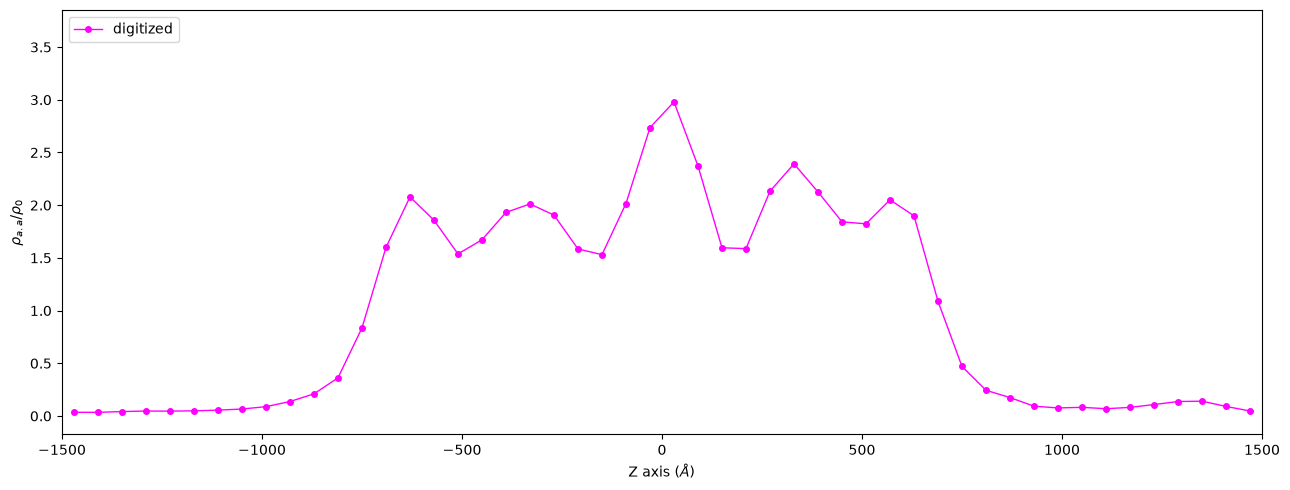

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Klf4 "single" (green) curve, digitized from media/figures/20260824/mitzutani-klf4.png
# 50 uniform bins over z in [-1500, 1500] A  ->  centers at +-30, +-90, ..., +-1470
klf4_single_z = np.arange(-1470.0, 1471.0, 60.0)          # Angstrom
klf4_single_rho = np.array([                               # rho_aa / rho_0
    0.0354, 0.0347, 0.0420, 0.0473, 0.0461, 0.0492, 0.0556, 0.0660,
    0.0886, 0.1373, 0.2099, 0.3619, 0.8355, 1.5988, 2.0778, 1.8576,
    1.5375, 1.6715, 1.9317, 2.0119, 1.9061, 1.5849, 1.5305, 2.0159,
    2.7357, 2.9800, 2.3724, 1.5959, 1.5880, 2.1326, 2.3918, 2.1261,
    1.8420, 1.8230, 2.0505, 1.8990, 1.0887, 0.4698, 0.2443, 0.1745,
    0.0933, 0.0764, 0.0822, 0.0691, 0.0816, 0.1084, 0.1373, 0.1405,
    0.0908, 0.0477,
])

# --- overlay against the original figure ---------------------------------
IMG = "media/figures/20260824/mitzutani-klf4.png"
# pixel bounds of the axes frame and the tick calibration used for digitizing
TOP, BOT, LEFT, RIGHT = 184, 862, 362, 2069
px = np.polyfit([362.0, 2069.5], [-1500.0, 1500.0], 1)          # col -> z
py = np.polyfit([328.0, 494.5, 664.0, 833.5], [3., 2., 1., 0.], 1)  # row -> rho

x0, x1 = np.polyval(px, [LEFT - 0.5, RIGHT + 0.5])
y0, y1 = np.polyval(py, [BOT + 0.5, TOP - 0.5])

fig, ax = plt.subplots(figsize=(13, 5))
# ax.imshow(np.asarray(Image.open(IMG))[TOP:BOT + 1, LEFT:RIGHT + 1],
#           extent=[x0, x1, y0, y1], aspect="auto")
ax.plot(klf4_single_z, klf4_single_rho + 0.0, "o-", color="magenta",
        ms=4, lw=1.0, label="digitized")
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_xlabel(r"Z axis ($\AA$)")
ax.set_ylabel(r"$\rho_{a.a}/\rho_0$")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


right edge             rho_d=2.07+-0.06  rho_l=0.104+-0.037  z0= 695.0+-8.0  ell= 70.8+-14.1 A
left edge (mirrored)   rho_d=1.85+-0.06  rho_l=0.074+-0.040  z0= 745.9+-8.4  ell= 63.0+-15.3 A
slab (5 par)           rho_d=2.00+-0.06  rho_l=0.088+-0.056  zL=-738  zR=700  ell=69.5+-20.4 A  |  slab width 1438 A


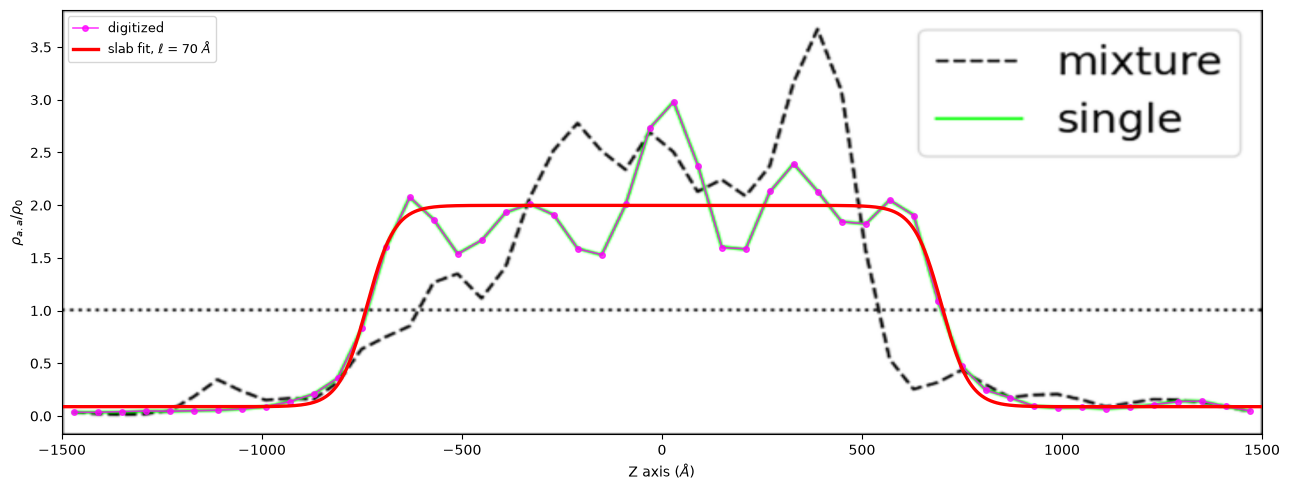

In [ ]:
from scipy.optimize import curve_fit

# --- models ---------------------------------------------------------------
def tanh_interface(z, rho_d, rho_l, z0, ell):
    """The model as given: single interface, rho_d at -inf -> rho_l at +inf."""
    return 0.5 * (rho_d + rho_l) - 0.5 * (rho_d - rho_l) * np.tanh((z - z0) / ell)

def tanh_slab(z, rho_d, rho_l, zL, zR, ell):
    """Two such interfaces back to back, sharing rho_d, rho_l and ell."""
    return rho_l + 0.5 * (rho_d - rho_l) * (np.tanh((z - zL) / ell)
                                            - np.tanh((z - zR) / ell))

# --- fits -----------------------------------------------------------------
# each edge on its own, using the literal single-interface model.
# the left edge is ascending, so it is fitted in the mirrored coordinate -z.
mR = klf4_single_z >= 330.0
mL = klf4_single_z <= -330.0
pR, cR = curve_fit(tanh_interface, klf4_single_z[mR], klf4_single_rho[mR],
                   p0=[2.0, 0.05, 700.0, 100.0], maxfev=40000)
pL, cL = curve_fit(tanh_interface, -klf4_single_z[mL], klf4_single_rho[mL],
                   p0=[2.0, 0.05, 700.0, 100.0], maxfev=40000)
# whole profile at once
ps, cs = curve_fit(tanh_slab, klf4_single_z, klf4_single_rho,
                   p0=[2.0, 0.05, -700.0, 700.0, 100.0], maxfev=40000)

for name, p, c in [("right edge", pR, cR), ("left edge (mirrored)", pL, cL)]:
    e = np.sqrt(np.diag(c))
    print(f"{name:22s} rho_d={p[0]:.2f}+-{e[0]:.2f}  rho_l={p[1]:.3f}+-{e[1]:.3f}"
          f"  z0={p[2]:6.1f}+-{e[2]:.1f}  ell={p[3]:5.1f}+-{e[3]:.1f} A")
es = np.sqrt(np.diag(cs))
print(f"{'slab (5 par)':22s} rho_d={ps[0]:.2f}+-{es[0]:.2f}  rho_l={ps[1]:.3f}+-{es[1]:.3f}"
      f"  zL={ps[2]:.0f}  zR={ps[3]:.0f}  ell={ps[4]:.1f}+-{es[4]:.1f} A"
      f"  |  slab width {ps[3]-ps[2]:.0f} A")

# --- same overlay as before, plus the fits --------------------------------
fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(np.asarray(Image.open(IMG))[TOP:BOT + 1, LEFT:RIGHT + 1],
          extent=[x0, x1, y0, y1], aspect="auto")
ax.plot(klf4_single_z, klf4_single_rho, "o-", color="magenta",
        ms=4, lw=1.2, alpha=0.75, label="digitized")

zf = np.linspace(x0, x1, 1200)
ax.plot(zf, tanh_slab(zf, *ps), "-", color="red", lw=2.4,
        label=rf"slab fit, $\ell$ = {ps[4]:.0f} $\AA$")
zr = np.linspace(330, x1, 400)
zl = np.linspace(x0, -330, 400)
# ax.plot(zr, tanh_interface(zr, *pR), "--", color="blue", lw=2.2,
#         label="single tanh, each edge")
# ax.plot(zl, tanh_interface(-zl, *pL), "--", color="blue", lw=2.2)

ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_xlabel(r"Z axis ($\AA$)")
ax.set_ylabel(r"$\rho_{a.a}/\rho_0$")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()


In [ ]:
slab_width = (ps[3]-ps[2])/10   # nm
vol = 30*30*slab_width * 1e-24
nklf4 = 184
c_dense = nklf4 / (vol * 6.022e23)  # Molar
es[3]+es[2]

np.float64(31.723825871097812)

#### Estimating kappa from interface width

In [4]:
v_tf   = 67.0      # Klf4 protein, nm^3
kT = 1.0
inds = [0, 10, 25, 45]
nb = 4000  # Klf4
# nb = 1000          # consistent with both v_tf / v_water and the measured c_dense
c_sat = 8000     # nanomolar
c_pw = c_sat/2  # nanomolar
c_dense = 2.4e6
delta_mu = kT*np.log(c_sat/c_pw)
phi_sat = to_phi(c_sat, v_tf)
phi_pw = to_phi(c_pw, v_tf)
phi_dense = to_phi(c_dense, v_tf)

chi, phi_d = calibrate(phi_sat, nb)
print("Chi (calibrated given nb): ", chi)
print("phi_dense (calibrated given nb): ", phi_d)
print("phi_dense (MD fit): ", phi_dense)
print("phi sat (given): ", phi_sat)
print("phi pw (given): ", phi_pw)

R = 40   # nm
print("R: ", R)

# vol fracs at edges of interface
phi_10 = phi_sat + 0.1*(phi_d - phi_sat)
phi_90 = phi_sat + 0.9*(phi_d - phi_sat)

# interface width from omega integral on a plane at equilibrium
mu_sat = nb*dfb(phi_sat, nb, chi)
mu_d = nb*dfb(phi_d, nb, chi)
print("mus equal: ", mu_sat, mu_d)
# domega  = lambda p: fb(p, nb, chi) - fb(phi_sat, nb, chi) + mu_sat*(p - phi_sat)/nb # kBT/b
phis_interface = np.linspace(phi_10, phi_90, 10000)
I = np.trapezoid((2*omega(phis_interface, phi_sat, nb, chi))**(-0.5), phis_interface) # (b/kBT)^1/2
v_water = 0.0297   # nm^3 
b = v_water**(1/3)  # nm
# l_interface_nm = 15.28  # nm
l_interface_nm = 15.0  # nm
print("Site length (nm): ", b)
print("Interface length (nm): ", l_interface_nm)
print("Interface length (sites): ", l_interface_nm / b)
l_interface_sites = l_interface_nm / b  # b (lattice site length)
kappa = (l_interface_sites / I)**2  # kBT / b
kappa_nm = kappa / b
print("kappa (kBT / site length): ", kappa)
print("kappa (kBT / nm): ", kappa_nm)

h0_lo, h0_hi, _, _ = h0_range(phi_pw, nb, chi, kappa=kappa, eps=1e-12)
print("h0_lo (kBT / site^2): ", h0_lo, "\nh0_hi (kBT / site^2): ", h0_hi)
print("h0_lo (kBT / nm^2): ", h0_lo/b**2, "\nh0_hi (kBT / nm^2): ", h0_hi/b**2)
print("kappa / h0_lo (sites): ", kappa / h0_lo)
# agreement with surface tension measurements
kBT = 4.11e-21 # J
phis_surf_tension = np.linspace(phi_sat, phi_d-1e-5, 5000)   # full range
I2 = np.trapezoid((2*kappa*omega(phis_surf_tension, phi_sat, nb, chi))**0.5, phis_surf_tension)
S = I2 * kBT * 1e18 * 1e6 / b**2
print("Surface tension (muN/m): ", S)   # muN/m
print("Surface energy (kBT): ", 4*np.pi*R**2*I2 / b**2)   # muN/m

Chi (calibrated given nb):  0.5280059665030825
phi_dense (calibrated given nb):  0.06943573415775697
phi_dense (MD fit):  0.09683376000000003
phi sat (given):  0.00032277920000000005
phi pw (given):  0.00016138960000000002
R:  40
mus equal:  -1895.0867855775293 -1895.0867855775289
Site length (nm):  0.3096840346369102
Interface length (nm):  15.0
Interface length (sites):  48.43646530757321
kappa (kBT / site length):  5.1864003219363894
kappa (kBT / nm):  16.74739328431056
h0_lo (kBT / site^2):  0.010512446434437429 
h0_hi (kBT / site^2):  0.010996683125564748
h0_lo (kBT / nm^2):  0.10961403453606001 
h0_hi (kBT / nm^2):  0.11466320531813191
kappa / h0_lo (sites):  493.3580736208468
Surface tension (muN/m):  16.80575084962221
Surface energy (kBT):  82.21403158304011


### Prewetting graphical construction

NameError: name 'phi_surf' is not defined

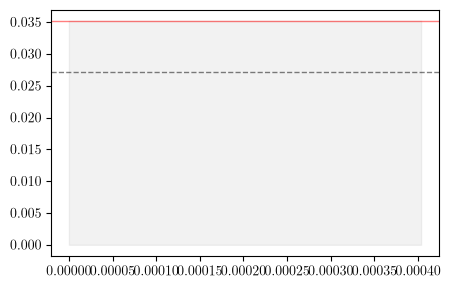

In [222]:
###### Graphical construction

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,1,figsize=(5,3.2))

ax.axhline(hline, color="black", lw=1.0, 
           linestyle="dashed", alpha=0.5)

ax.fill_between(phis, 0, init_energy_lo, color="black", alpha=0.05)
ax.axhline(init_energy_lo, color="red", alpha=0.5, lw=1)

labels = [r"$\mu > \mu_*$", 
          r"$\mu = \mu_*$", 
          r"$\mu_{\rm sat} < \mu < \mu_*$", 
          r"$\mu = \mu_{\rm sat}$"]

locs = [(0.3, 0.045), (0.45, 0.04), (0.57, 0.031), (0.7, 0.02)]

for i, mu in enumerate(mus):
    args = (mu, chi, T, nb, c0)
    min_ = np.argmin(dfb(phis, nb, chi))
    phi_inf = phis[min_]
    phi_surf_i = phi_surf[inds[i]]
    dF = F(phis, *args) - F(phi_inf, *args)
    ax.plot(phis, dF, lw=1, color="black", alpha=(i+1)/4, label=labels[i])
    # ax.text(locs[i][0], locs[i][1], labels[i], fontsize=12)
    
    if i == 2:
        intersect = np.where(np.abs(-dF + hline) < 5e-6)[0]
        xi = phis[intersect-1]
        print(xi)
        yi = hline
        ax.scatter(xi[0], yi, color="black")
        ax.scatter(xi[-1], yi, color="black")

    if i == 0:
        intersect = np.where(np.abs(-dF + init_energy_lo) < 5e-6)[0]
        xi = phis[intersect-1]
        print(xi)
        yi = init_energy_lo
        ax.scatter(xi[0], yi, color="black", alpha=0.25)

ax.set_xlabel(r"Volume fraction $\phi$", fontsize=12)
ax.set_ylabel(r"$f(\phi) - f(\phi_\infty)$", fontsize=12)
ax.text(0.4, 0.0543, r"$h_*^2/2\kappa$", fontsize=12, color="red")
ax.plot((0.32, 0.38), (0.0557, 0.0557), color="red", lw=0.9)

lg = ax.legend(fontsize=10.5, edgecolor="none", framealpha=0)
ax.set_ylim(0, 0.06)
ax.set_xlim(0, 0.83)


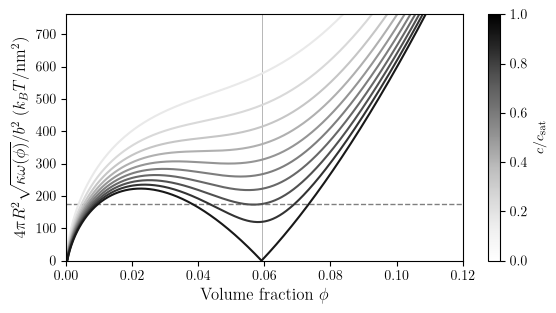

In [ ]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,1, figsize=(6.4, 3.2))

def xi_of(z, phi, phi_inf, thresh=0.1):
    rel   = (phi - phi_inf) / phi_inf
    inner = rel[:-1]
    k = int(np.argmax(inner < thresh))
    if inner[k] >= thresh:
        return np.nan
    if k == 0:
        return 0.0
    r0, r1 = rel[k-1], rel[k]
    return z[k-1] + (thresh - r0) / (r1 - r0) * (z[k] - z[k-1])

runs = [("data/20260825/large_R/demo_bvp_profiles.json", 200)]

sweep_fracs = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

phi_infs  =  np.linspace(1e-6, phi_sat, 1000)    # np.array(d["phi_inf"])
norm = plt.Normalize(vmin=0, vmax=1)
cmap = mpl.cm.Greys
phis = np.linspace(5e-9, 1-5e-9, 5000)
inds = [int(np.argmin(np.abs(phi_infs/phi_sat - t))) for t in sweep_fracs]
phi_inf_sample  = phi_infs[inds]

ax.axhline(4*np.pi*R**2*(h0_lo/np.sqrt(2*kappa))/v_water**(1/2), color="black", lw=1.0,
           linestyle="dashed", alpha=0.5)

ax.axvline(phi_d, color="black", lw=0.5, alpha=0.4)

for i, idx in enumerate(inds):
    ax.plot(phis, 4*np.pi*R**2*np.sqrt(kappa*omega(phis, phi_infs[idx], nb, chi))/v_water**(2/3), lw=1.5, color=cmap(norm((i+2)/(len(inds)+2))))

ax.set_xlabel(r"Volume fraction $\phi$", fontsize=12)
ax.set_ylabel(r"$4\pi R^2\sqrt{\kappa\omega(\phi)}/b^2 \; (k_BT / {\rm nm}^2)$", fontsize=12)
ax.set_ylim(0, 4*np.pi*R**2*2.0e-3/v_water)
ax.set_xlim(0, 0.12)
I2 = np.trapezoid((2*kappa*omega(phis_surf_tension, phi_sat, nb, chi))**0.5, phis_surf_tension)

# print(f"{'run':9s} {'R':>7s} {'mu':>8s} {'phi_inf':>10s} {'c_inf/nM':>9s} "
#       f"{'phi_s':>8s} {'xi':>7s} {'R/xi':>7s}  conv")

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax, label=r'$c/c_{\rm sat}$')

In [ ]:
out_dir = "media/figures/20260821"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "pw_graphical.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260821/pw_graphical.pdf


### Influence of curvature 

In [240]:
T = 1.0
v_tf = 67    # nm^3
inds = [0, 10, 25, 45]
nb = 2230
c_sat = 2000     # nanomolar
c_pw = 1000  # nanomolar
kappa = 1
delta_mu = T*np.log(c_sat/c_pw)
phi_sat = to_phi(c_sat, v_tf)
phi_pw = to_phi(c_pw, v_tf)
chi, phi_d = calibrate(phi_sat, nb)
h0_lo, h0_hi, _, _ = h0_range(phi_pw, nb, chi, kappa=kappa, eps=1e-12)
mu_sat = -nb*dfb(phi_d, nb, chi)
mu_pw = -nb*dfb(phi_pw, nb, chi)
mus = np.array([0.75*mu_pw,  mu_sat])
h0 = h0_lo 
phis = np.linspace(5e-9, 1-5e-9, 5000)
init_energy = h0**2/(2*kappa)
init_energy_lo = h0_lo**2/(2*kappa)
init_energy_hi = h0_hi**2/(2*kappa)
hline = init_energy

In [241]:
print("h0_lo: ", h0_lo, "\n", 
      "h0_hi: ", h0_hi, "\n", 
      "chi: ", chi, "\n", 
      "h0: ", -h0_lo, "\n",
      "phi_d: ", phi_d, "\n", 
      "phi_sat: ", phi_sat, "\n", 
      "phi_pw: ", phi_pw, "\n",
      "mu_sat: ", mu_sat, "\n")

h0_lo:  0.008143148291991899 
 h0_hi:  0.009673323326128934 
 chi:  0.544821635760637 
 h0:  -0.008143148291991899 
 phi_d:  0.11211404241993071 
 phi_sat:  8.069480000000001e-05 
 phi_pw:  4.0347400000000006e-05 
 mu_sat:  1023.4887126671289 



run             R       mu    phi_inf  c_inf/nM    phi_s      xi    R/xi  conv


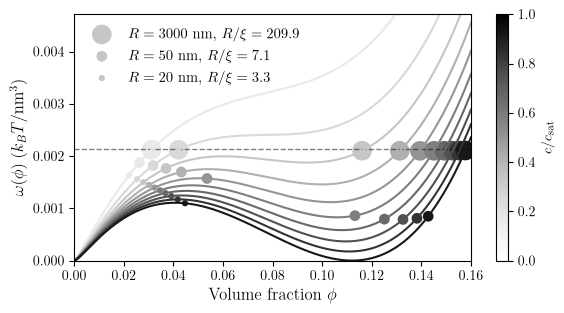

In [ ]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,1, figsize=(6.4, 3.2))

# xi = min{z : (phi(z) - phi_inf)/phi_inf < thresh}, with the crossing interpolated.
# The old expression, argmin(np.abs(phi - phi_inf)/phi_inf - 0.5), had np.abs closing
# before the -0.5, so it just sought the SMALLEST relative excess: it returned the
# first z where phi - phi_inf underflows to 0.0 (15-25% high), and clamped at L once
# the profile never gets there.  z = L is excluded below because the BVP pins it to
# phi_inf by the boundary condition -- a crossing there means L is too short to
# resolve xi, which is reported as nan rather than as xi = L.
def xi_of(z, phi, phi_inf, thresh=0.1):
    rel   = (phi - phi_inf) / phi_inf
    inner = rel[:-1]
    k = int(np.argmax(inner < thresh))
    if inner[k] >= thresh:
        return np.nan
    if k == 0:
        return 0.0
    r0, r1 = rel[k-1], rel[k]
    return z[k-1] + (thresh - r0) / (r1 - r0) * (z[k] - z[k-1])

# runs = [("data/20260821/large_R/demo_bvp_profiles.json", 200),
#         ("data/20260821/med_R/demo_bvp_profiles.json",    60),
#         ("data/20260821/small_R/demo_bvp_profiles.json",  20)]

# runs = [("data/20260825/demo_bvp_profiles.json", 200)]

runs = [("data/20260825/large_R/demo_bvp_profiles.json", 200),
        ("data/20260825/medium_R/demo_bvp_profiles.json",    60),
        ("data/20260825/small_R/demo_bvp_profiles.json",  20)]

# Fractions along the swept phi_inf axis at which to draw the construction.  The mu
# values are read back OUT of the sweep rather than taken from the calibration cell
# above, so each marker necessarily sits on the curve the BVP actually solved at
# (the calibration cell is free to drift to another system without silently
# collapsing every marker onto the nearest sampled mu).
sweep_fracs = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
# sweep_fracs = np.linspace(0.1, 0.9, 10)

# Bulk parameters come from the run provenance for the same reason.  These globals
# stay bound to the first run, as before, since other cells read phi_surf / phi_full
# / phi_infs / z_full.
path      = runs[0][0]
d         = json.load(open(path))
p         = d["params"]["surface"]
bc_reg    = d["params"]["bvp"]["bc_reg"]
mu_infs   = np.array(d["mu_inf"])
phi_infs  = np.array(d["phi_inf"])
phi_full  = np.array(d["phi_profiles_full"])
phi_surf  = phi_full[:, 0]
z_full    = np.array(d["z_full"])

T, c0 = 1.0, 1
nb, chi, kappa, h0 = p["nb"], p["chi_b"], p["kappa"], p["omega_b"]
phis = np.linspace(5e-9, 1-5e-9, 5000)

inds = [int(np.argmin(np.abs(phi_infs/d["binodal"] - t))) for t in sweep_fracs]
phi_inf_sample  = phi_infs[inds]

ax.axhline(h0**2/(2*kappa)/v_water, color="black", lw=1.0,
           linestyle="dashed", alpha=0.5)

for i, idx in enumerate(inds):
    ax.plot(phis, omega(phis, phi_infs[idx], nb, chi)/v_water, lw=1.5, color=cmap(norm((i+2)/(len(inds)+2))))

ax.set_xlabel(r"Volume fraction $\phi$", fontsize=12)
ax.set_ylabel(r"$\omega(\phi) \; (k_BT / {\rm nm}^3)$", fontsize=12)
ax.set_ylim(0, 1.4e-4/v_water)
ax.set_xlim(0, 0.16)

print(f"{'run':9s} {'R':>7s} {'mu':>8s} {'phi_inf':>10s} {'c_inf/nM':>9s} "
      f"{'phi_s':>8s} {'xi':>7s} {'R/xi':>7s}  conv")

norm = plt.Normalize(vmin=0, vmax=1)
cmap = mpl.cm.Greys

for path, size in runs:
    dd  = json.load(open(path))
    zz  = np.array(dd["z_full"])
    pf  = np.array(dd["phi_profiles_full"])
    # pin = np.array(dd["phi_inf"])
    mi  = np.array(dd["mu_inf"])
    ok  = np.array(dd["success"])
    R   = dd["R"]
    tag = path.split("/")[-2]
    for i, idx in enumerate(inds):
        # args    = (mu, chi, T, nb, c0)
        # idx     = int(np.argmin(np.abs(mi + mu)))   # same phi_inf grid across runs
        phi_inf_i = phi_infs[idx]
        phi_s   = pf[idx, 0]
        xi      = xi_of(zz, pf[idx], phi_inf_i)
        # phi_ref = phis[np.argmin(F(phis, *args))]
        lab = rf"$R={R*0.3:.0f}$ nm, $R/\xi={R/xi:.1f}$" if np.isfinite(xi) else rf"$R={R*0.3:g}$ nm, $\xi$ unresolved"
        if i == 2:
            ax.scatter(phi_s, omega(phi_s, phi_inf_i, nb, chi)/v_water, s=size,
                        color=cmap(norm((i+2)/(len(inds)+2))), label=lab,edgecolor="none")
        else:
            ax.scatter(phi_s, omega(phi_s, phi_inf_i, nb, chi)/v_water, s=size,
                        color=cmap(norm((i+2)/(len(inds)+2))),edgecolor="none")
        
        # print(f"{tag:9s} {R:7g} {mi[idx]:8.4f} {phi_inf_i:10.3e} {to_nM(phi_inf_i, v_tf):9.1f} "
        #       f"{phi_s:8.4f} {xi:7.3f} {R/xi:7.2f}  {ok[idx]}")

# ax.plot((0.6, 0.66), (0.223, 0.223), color="black", lw=0.9, alpha=0.3)
# ax.text(0.7, 0.217, r"$0.1c_{\rm sat}$", fontsize=12, color="black")

# ax.plot((0.6, 0.66), (0.198, 0.198), color="black", lw=0.9, alpha=0.66)
# ax.text(0.7, 0.192, r"$0.3c_{\rm sat}$", fontsize=12, color="black")

# ax.plot((0.6, 0.66), (0.175, 0.175), color="black", lw=0.9, alpha=1)
# ax.text(0.7, 0.169, r"$0.7c_{\rm sat}$", fontsize=12, color="black")

ax.legend(fontsize=10.5, edgecolor="none", framealpha=0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax, label=r'$c/c_{\rm sat}$')

In [66]:
out_dir = "media/figures/20260825"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "pw_curvature3.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260825/pw_curvature3.pdf


### Single sphere from numerical solver

8.069480000000957e-05


{'eps': 1e-08,
 'parallel_plates': False,
 'chi_b': 0.544821635760637,
 'omega_b': -0.0358,
 'kappa': 10.12228759025409,
 'phi_inf': 0.09,
 'L': 200.0,
 'R': 100.0,
 'conserve_volume': False,
 'nb': 2230.0}

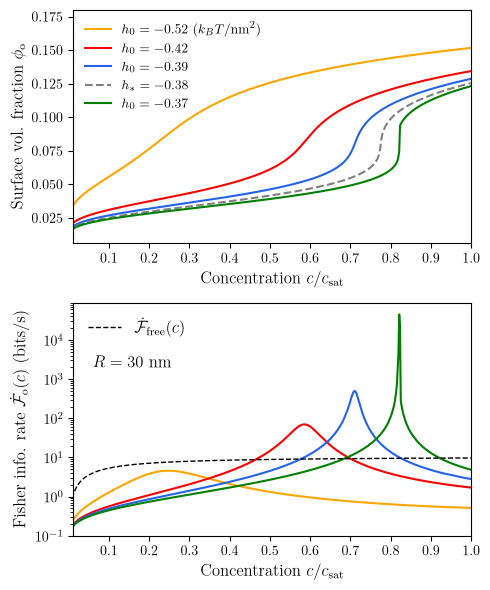

In [ ]:
import json, numpy as np
import matplotlib.pyplot as plt

# path = "data/20260723/demo_bvp_profiles.json"
# path = "data/20260727/demo_bvp_profiles.json"
# path = "data/20260728/run3/demo_bvp_profiles.json"
# path = "data/20260822/run1/demo_bvp_profiles.json"
path = "data/20260825/run1/demo_bvp_profiles.json"
# path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
d = json.load(open(path))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
chi = d["chi"]
binodal = d["binodal"]

fig, ax = plt.subplots(2, 1, figsize=(5, 6))
k = 0
# ax[0].plot(z_full, phi_full.T, color="#2563EB", lw=0.5)
# ax[0].set_xlabel(r"Distance from surface $z$", fontsize=12)
# ax[0].set_ylabel(r"Profile $\phi$", fontsize=12)
# ax[0].set_xlim(0, z_full[-1]); 
# ax[0].grid(alpha=0.3)

colors = ["orange", "red", "#2563EB", "gray", "green"]
for i, run in enumerate([1,2,3,4,5]):

    # path = f"data/20260804/run{run}/demo_bvp_profiles.json"
    # path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
    # path = f"data/20260727/demo_bvp_profiles.json"
    # path = f"data/20260822/run{run}/demo_bvp_profiles.json"
    path = f"data/20260825/run{run}/demo_bvp_profiles.json"
    d = json.load(open(path))
    phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
    mu_inf  = np.array(d["mu_inf"])                       # (n_phi,)
    z_full   = np.array(d["z_full"])                        # (n_z,)
    z_lin    = np.array(d["z_linear"])                      # (n_z,)
    phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
    phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
    R, omega_b = d["R"], d["omega_b"]
    h0 = d["params"]["surface"]["omega_b"]
    chi = d["chi"]

    phi_surf = phi_full.T[0,:]
    # ax[0].set_xticks(xticks/1000)
    # ax[0].set_xticklabels(xticks)
    if i == 0:
        ax[0].plot(phi_inf/binodal, phi_surf, color=colors[i], label=rf"$h_0={h0/b**2:.2f}$ ($k_BT/$nm$^2$)")
    elif i == 3:
        ax[0].plot(phi_inf/binodal, phi_surf, color=colors[i], linestyle="dashed", label=rf"$h_*={h0/b**2:.2f}$")
    else:
        ax[0].plot(phi_inf/binodal, phi_surf, color=colors[i], label=rf"$h_0={h0/b**2:.2f}$")
    # ax[0].set_xlabel(r"Concentration $c\times 10^{-3}$", fontsize=12)
    ax[0].set_ylabel(r"Surface vol. fraction $\phi_{\rm o}$", fontsize=12)

    a = 3e-3        # um / 10 bp
    D_tf = 7.4      # um^2/s
    kb = 4*a*D_tf   # um^3/s
    K_D = 0.1*to_nM(binodal, v_tf)*1e-24*6.022e23
    ku = kb*K_D
    c_inf = to_nM(phi_inf, v_tf)*1e-24*6.022e23   # particles / um^3
    c_surf = to_nM(phi_surf, v_tf)*1e-24*6.022e23   # particles / um^3

    tau_free = 1 / (kb*c_inf) + 1 / ku
    tau = 1 / (kb*c_surf) + 1 / ku
    dphi_surf = np.gradient(phi_surf, phi_inf)
    phi_surf_gain = (dphi_surf * phi_inf / phi_surf) ** 2
    fisher_rate_one_sphere = phi_surf_gain / tau

    if i != 3:
        ax[1].plot(phi_inf/binodal, fisher_rate_one_sphere, color=colors[i])

xticks = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
ax[0].set_xticks(xticks)
ax[0].set_xticklabels(xticks)
ax[0].set_xlim(0.01, 1.0)
ax[0].set_ylim(None, 0.18)
ax[0].set_xlabel(r"Concentration $c/c_{\rm sat}$", fontsize=12)
lg0 = ax[0].legend(fontsize=9.5, edgecolor="none")
lg0.get_frame().set_alpha(None)
lg0.get_frame().set_facecolor((0, 0, 1, 0.0))
ax[1].plot(phi_inf/binodal, 1/tau_free, linestyle="dashed", color="black",
        label=r"$\dot{\mathcal{F}}_{\rm free}(c)$", lw=1)
ax[1].set_yscale('log')
ax[1].set_ylabel(r"Fisher info. rate $\dot{\mathcal{F}}_{\rm o}(c)$ (bits/s)", fontsize=12)
ax[1].set_xlabel(r"Concentration $c/c_{\rm sat}$", fontsize=12)
ax[1].set_ylim(0.1, None)
ax[1].text(0.06, 2e3, rf"$R={R*0.3:g}$ nm", fontsize=12)
 
ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)
ax[1].set_xlim(0.01, 1.0)
# ax[1].grid(alpha=0.4)
ax[1].legend(fontsize=12, loc="upper left", edgecolor="none")

# fig.suptitle(rf"$R={R*0.3}$, $h_0={omega_b}$, $\chi = {chi}$")
fig.tight_layout()
print(binodal)
# print(phi_inf)
d["params"]["surface"]

In [167]:
out_dir = "media/figures/20260825"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "surface_fisher_3vals.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260825/surface_fisher_3vals.pdf


#### Single plate - SI

equil. concentration 5e-09
equil. concentration 5e-09
equil. concentration 5e-09
binodal:  0.881763523236473


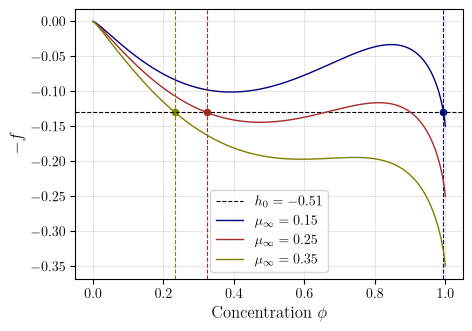

In [ ]:
###### Plot

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

# mus = [0.3, 0.4, 0.5]
c = ["navy", "brown", "olive"]

init_energy = h0**2/(2*kappa)
ax.axhline(-init_energy, color="black", lw=0.8, 
           linestyle="dashed", label=rf"$h_0 = {h0}$")

for i, mu in enumerate(mus):
    min_ = np.argmin(F(phis, mu, chi, T, nb, c0))
    phi_inf = phis[min_]
    dF = F(phis, mu, chi, T, nb, c0) - F(phi_inf, mu, chi, T, nb, c0)
    ax.plot(phis, -dF, color=c[i], lw=1, label=rf"$\mu_\infty={mus[i]}$")
    intersect = np.argmin(np.abs(-dF + init_energy))
    xi = phis[intersect]
    yi = -init_energy
    ax.scatter(xi, yi, color=c[i], s=20)
    ax.axvline(xi, color=c[i], lw=0.8, linestyle="dashed")

    print("equil. concentration", phi_inf)

ax.set_xlabel(r"Concentration $\phi$", fontsize=12)
ax.set_ylabel(r"$-f$", fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend()

# ultra zoom in
# ax.set_xlim(-1e-5, 4e-4)
# ax.set_ylim(-1e-5, 1e-6)

min_ = np.argmin(F(phis, 0, chi, T, nb, c0))
phi_inf = phis[min_]
print("binodal: ", phi_inf)


In [ ]:
out_dir = "media/figures/20260801"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "prewetting_potentials_demo.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260801/prewetting_potentials.pdf


In [ ]:
### With volume conservation

# if sol is not None:
#     if len(sol) == 2:
#         ax.axvline(x=sol[0], lw=1)
#         ax.axvline(x=sol[1], lw=1)
#     elif len(sol) == 1:
#         ax.axvline(x=sol[0], lw=1)

#### Parallel plates

In [77]:
import numpy as np
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq

# =============================================================================
# Mechanical analogy for  kappa phi'' = F'(phi)  (z plays the role of time):
#   particle of mass kappa in the potential  V(phi) = -F(phi),  plotted below.
#   BC at the plate:  phi'(0) = h0/kappa   ->   K0 = h0^2/(2 kappa).
# A symmetric profile between plates a distance d apart leaves phi_fp, turns
# around exactly once, and returns to phi_fp at z = d with phi'(d) = -h0/kappa.
# So the condition is  period(phi_fp) = d,  which we get from energy
# conservation as a quadrature instead of by shooting.
#   E - V(phi) = F(phi) - F(phi_fp) + K0 =: w(phi)
#   period = 2 * sqrt(kappa/2) * int_{phi_fp}^{phi_turn} dphi / sqrt(w(phi))
# =============================================================================

EPS = 1e-12

def F(phi, *args):
    mu, chi, T, nb, c0 = args
    return mu*phi + T*c0*(chi*phi*(1-phi) + (phi*np.log(phi)/nb + (1-phi)*np.log(1-phi)))

def dFdphi(phi, *args):
    mu, chi, T, nb, c0 = args
    return mu + T*c0*(chi*(1-2*phi) + (np.log(phi) + 1)/nb - np.log(1-phi) - 1)

def extrema(args, n=4001):
    """Extrema of F: roots of F' bracketed on a grid, then polished.
    Robust to F having 0, 1, 2 or 3 of them (unlike diffing sign(diff(F)))."""
    p = np.linspace(1e-9, 1 - 1e-9, n)
    v = dFdphi(p, *args)
    k = np.where(np.sign(v[:-1]) * np.sign(v[1:]) < 0)[0]
    return np.array([brentq(dFdphi, p[i], p[i+1], args=args, xtol=1e-14) for i in k])

def turning_point(phi0, h0, kappa, args, n=2000):
    """First phi past phi0 (travelling in the direction sign(h0)) where the
    particle runs out of kinetic energy. NaN if it escapes (0,1) instead."""
    K0 = h0**2 / (2*kappa)
    f0 = F(phi0, *args)
    w = lambda p: F(p, *args) - f0 + K0
    end = (1 - EPS) if h0 > 0 else EPS
    p = np.linspace(phi0, end, n)                 # ordered along direction of travel
    v = w(p)
    k = np.where(np.sign(v[:-1]) * np.sign(v[1:]) < 0)[0]
    if len(k) == 0:
        return np.nan
    a, b = sorted((p[k[0]], p[k[0]+1]))
    return brentq(w, a, b, xtol=1e-14)

def period(phi0, h0, kappa, args):
    """Round-trip z-distance: leave phi0, turn around once, return to phi0.
    NaN if unbounded, inf if the turning point is an extremum of F (homoclinic:
    the particle takes forever to arrive, so the film is infinitely thick)."""
    phi_t = turning_point(phi0, h0, kappa, args)
    if not np.isfinite(phi_t):
        return np.nan
    slope = abs(dFdphi(phi_t, *args))             # = |w'(phi_t)|
    if slope < 1e-12:
        return np.inf
    K0, f0 = h0**2/(2*kappa), F(phi0, *args)
    a, b = sorted((phi0, phi_t))
    up = phi_t > phi0
    # w vanishes linearly at phi_t, so sqrt(dist/w) is smooth there (-> 1/sqrt(slope));
    # hand the 1/sqrt endpoint singularity to quad's algebraic weight rather than
    # letting the integrand blow up numerically.
    def smooth(p):
        w = F(p, *args) - f0 + K0
        dist = (b - p) if up else (p - a)
        return np.sqrt(kappa/2) * np.sqrt(1.0/slope if (w <= 0 or dist <= 0) else dist/w)
    val, _ = quad(smooth, a, b, weight='alg',
                  wvar=((0.0, -0.5) if up else (-0.5, 0.0)), limit=2000)
    return 2.0 * val

def fixed_points(d, h0, kappa, args, n=800, lo=1e-6, hi=1-1e-6):
    """Every phi_fp with period(phi_fp) == d. Returns (roots, grid, periods)."""
    p = np.linspace(lo, hi, n)
    Tg = np.array([period(x, h0, kappa, args) for x in p])
    g = Tg - d
    roots = [brentq(lambda x: period(x, h0, kappa, args) - d, p[i], p[i+1], xtol=1e-12)
             for i in range(len(p)-1)
             if np.isfinite(g[i]) and np.isfinite(g[i+1]) and g[i]*g[i+1] < 0]
    return np.array(roots), p, Tg

def profile(z, phi0, h0, kappa, args, rtol=1e-10, atol=1e-12):
    """phi(z) by direct integration -- used only to verify a root, not to find one."""
    rhs = lambda _, y: (y[1], dFdphi(min(max(y[0], EPS), 1-EPS), *args)/kappa)
    s = solve_ivp(rhs, (z[0], z[-1]), [phi0, h0/kappa], t_eval=z, rtol=rtol, atol=atol)
    return s.y[0], s.y[1]

In [78]:
###### Parameters
T, nb, chi, c0, kappa = 1.0, 1, 2.5, 1.0, 1
mus = np.array([0.05, 0.1])
h0 = -0.3
d = 3
phis = np.linspace(5e-9, 1 - 5e-9, 500)
K0 = h0**2 / (2*kappa)

mu=0.05: 1 fixed point(s)
   phi_fp=0.9675854469  phi_turn=0.8550162586   check: phi(d)-phi(0)=+1.70e-09, phi'(d)=+0.30000001 (want +0.30000000)
mu=0.1: 3 fixed point(s)
   phi_fp=0.3516554714  phi_turn=0.1552496822   check: phi(d)-phi(0)=+5.38e-11, phi'(d)=+0.30000000 (want +0.30000000)
   phi_fp=0.5471988707  phi_turn=0.2855557840   check: phi(d)-phi(0)=+3.55e-11, phi'(d)=+0.30000000 (want +0.30000000)
   phi_fp=0.9613119549  phi_turn=0.8404633341   check: phi(d)-phi(0)=+1.03e-09, phi'(d)=+0.30000000 (want +0.30000000)


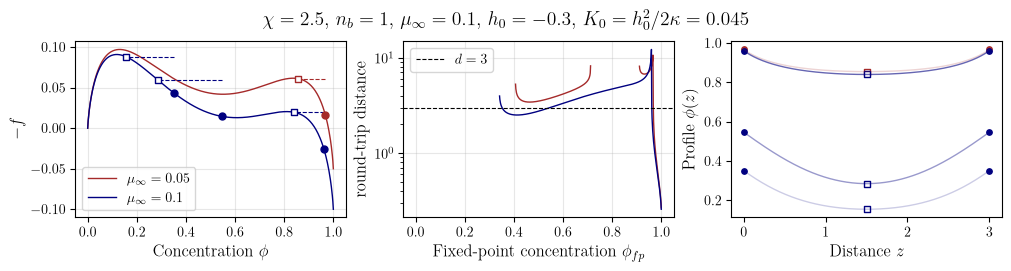

In [79]:
###### Plot
plt.rcParams.update({"text.usetex": True, "font.family": "serif"})
fig, (ax, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 2.6), layout="constrained")
c = ["brown", "navy", "olive"]

for i, mu in enumerate(mus):
    args = (mu, chi, T, nb, c0)

    # for e in extrema(args):
    #     ax.axvline(e, lw=0.8, color="black", alpha=0.4)

    ax.plot(phis, -F(phis, *args), color=c[i], lw=1, label=rf"$\mu_\infty={mu}$")

    roots, pgrid, Tg = fixed_points(d, h0, kappa, args)
    ax2.plot(pgrid, Tg, color=c[i], lw=1)

    print(f"mu={mu}: {len(roots)} fixed point(s)")
    for j, r in enumerate(roots):
        pt = turning_point(r, h0, kappa, args)
        zz = np.linspace(0, d, 2001)
        pz, dpz = profile(zz, r, h0, kappa, args)
        ax3.plot(zz, pz, color=c[i], lw=1, alpha=0.2*(j+1))
        ax3.scatter(0, pz[-1], color=c[i], s=15)
        ax3.scatter(d, pz[-1], color=c[i], s=15)
        ax3.scatter(d/2, pt, edgecolor=c[i], s=15, color="white", marker="s")
        print(f"   phi_fp={r:.10f}  phi_turn={pt:.10f}   "
              f"check: phi(d)-phi(0)={pz[-1]-r:+.2e}, "
              f"phi'(d)={dpz[-1]:+.8f} (want {-h0/kappa:+.8f})")

        ax.scatter(r,  -F(r,  *args), color=c[i], s=25, zorder=3)
        ax.scatter(pt, -F(pt, *args), edgecolor=c[i], color="white", s=25, zorder=3, marker="s")
        ax.plot([r, pt], [-F(r, *args) + K0]*2, color=c[i], lw=0.8, ls="dashed")
        # ax.axhline(-F(r, *args), color=c[i], lw=0.6, ls="dotted")

ax2.axhline(d, color="black", lw=0.8, ls="dashed", label=rf"$d={d}$")
ax.set_xlabel(r"Concentration $\phi$", fontsize=12)
ax.set_ylabel(r"$-f$", fontsize=12)
fig.suptitle(rf"$\chi = {chi}$, $n_b={nb}$, $\mu_\infty={mu}$, $h_0={h0}$, $K_0=h_0^2/2\kappa={K0:.3g}$", fontsize=14)
ax2.set_xlabel(r"Fixed-point concentration $\phi_{fp}$", fontsize=12)
ax2.set_ylabel("round-trip distance", fontsize=12)
ax2.set_yscale("log")
ax2.set_xlim(-0.05, 1.05)
ax3.set_ylabel(r"Profile $\phi(z)$", fontsize=12)
ax3.set_xlabel(r"Distance $z$", fontsize=12)
for a in (ax, ax2):
    a.grid(True, alpha=0.3)
    a.legend()

In [ ]:
out_dir = "media/figures/20260802"
os.makedirs(out_dir, exist_ok=True) 
out_path = os.path.join(out_dir, "parallel_plates_graphical_hi_c_low_h0_1.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260802/parallel_plates_graphical_hi_c_low_h0_1.pdf


### Parallel plates solver

3.787392948001521e-05


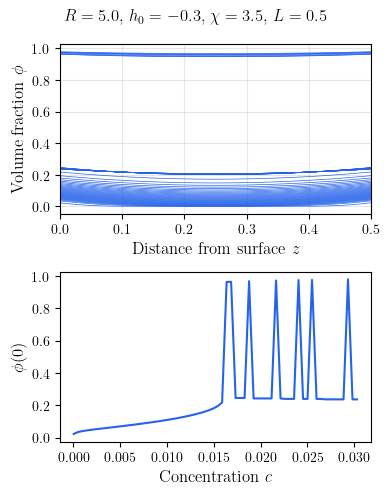

In [454]:
import json, numpy as np
import matplotlib.pyplot as plt

# path = "data/20260723/demo_bvp_profiles.json"
path = "data/20260727/demo_bvp_profiles.json"
d = json.load(open(path))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
chi = d["chi"]
L = d["L"]
# chi = 4

fig, ax = plt.subplots(2, 1, figsize=(4, 5))
k = 0
ax[0].plot(z_full, phi_full.T, color="#2563EB", lw=0.5)
ax[0].set_xlabel(r"Distance from surface $z$", fontsize=12)
ax[0].set_ylabel(r"Volume fraction $\phi$", fontsize=12)
ax[0].set_xlim(0, max(z_full)); 
ax[0].grid(alpha=0.3)

phi_surf = phi_full.T[0,:]
# ax[1].plot(phi_inf, np.gradient(np.gradient(phi_surf, phi_inf), phi_inf), color="#2563EB")  # curvature
# ax[1].axhline(0, lw=1, color="black", alpha=0.4)
ax[1].plot(phi_inf, phi_surf, color="#2563EB")
# ax[1].set_ylim(-5000, 5000)
ax[1].set_xlabel(r"Concentration $c$", fontsize=12)
ax[1].set_ylabel(r"$\phi(0)$", fontsize=12)

fig.suptitle(rf"$R={R}$, $h_0={omega_b}$, $\chi = {chi}$, $L={L}$")
fig.tight_layout()
print(phi_inf[k])